In [1]:
import os, sys

# Clone KEqL
REPO = "/content/kernelequationlearning"
if not os.path.isdir(REPO):
    !git clone -q https://github.com/TADSGroup/kernelequationlearning.git {REPO}

!pip install -q jaxopt
TOOLS = os.path.join(REPO, "keql_tools")
if TOOLS not in sys.path:
    sys.path.insert(0, TOOLS)
# !git clone -q https://github.com/TADSGroup/kernelequationlearning.git /content/kernelequationlearning
# !pip install -q jaxopt
# sys.path.insert(0, "/content/kernelequationlearning/keql_tools")

In [2]:
KEQL_PATH = "/content/kernelequationlearning/keql_tools"
import sys; sys.path.insert(0, KEQL_PATH)
import numpy as np
import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.interpolate import RectBivariateSpline
from Kernels import get_gaussianRBF
from parabolic_data_utils import (build_burgers_data, build_tx_grid_chebyshev,
                                  setup_problem_data, GP_Sampler_1D_Pinned)

INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#dcdcd6", "#fcfcfb"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"

def style(ax):
    ax.set_facecolor(SURF); ax.tick_params(colors=MUTED, labelsize=8)
    for s in ax.spines.values(): s.set_color(GRID)

def check(name, val, tol=1e-12):
    print(f"[{'OK ' if val <= tol else 'BAD'}] {name}: {val:.2e}")

# %%run_if <condition>: first line of a cell -> the cell runs only if the condition is true (else it prints "skipped")
from IPython.core.magic import register_cell_magic
@register_cell_magic
def run_if(line, cell):
    ip = get_ipython()
    if eval(line, ip.user_ns):
        ip.run_cell(cell)
    else:
        print(f"skipped (condition false: {line.strip()})")

/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data

  0%|          | 0/10099 [00:00<?, ?it/s]

  5%|▍         | 483/10099 [00:00<00:01, 4828.98it/s]

 10%|▉         | 966/10099 [00:00<00:01, 4814.96it/s]

 14%|█▍        | 1448/10099 [00:00<00:01, 4711.31it/s]

 19%|█▉        | 1920/10099 [00:00<00:01, 4695.59it/s]

...

 88%|████████▊ | 8887/10099 [00:01<00:00, 4687.46it/s]

 93%|█████████▎| 9370/10099 [00:01<00:00, 4725.19it/s]

 98%|█████████▊| 9869/10099 [00:02<00:00, 4799.73it/s]

100%|██████████| 10099/10099 [00:02<00:00, 4791.05it/s]

keql experiment 3B: kappa 0.001, alpha 5.0, 60 interior observations (PRNGKey(55))
[OK ] time grid  max|t_n - keql|: 0.00e+00
[OK ] space grid max|x_k - keql|: 1.67e-16
[OK ] observations on nodes: 1.67e-16
|Omega| = 141 (unique 141); boundary 52, initial 29, interior 60


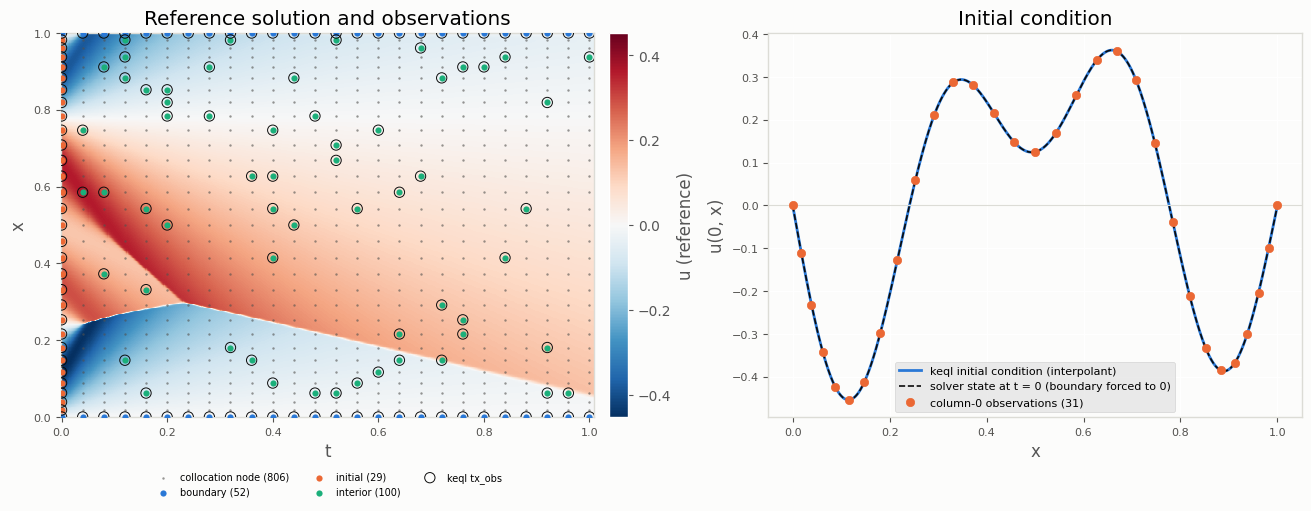

In [3]:
# keql setup
# Which keql experiment (paper Fig. 3):
#   "3A": benchmark_fixedICs/errors_curves.ipynb, one run: GP initial condition (seed 2), kappa = 0.01, alpha = 1,
#         100 interior observations drawn with PRNGKey(0)
#   "3B": oneshot_shock/onestep/compute.ipynb ("Ex. 1", shock): u0 = 0.25 (x sin(pi x) - sin(5 pi x) - sin(3 pi x)),
#         kappa = 0.001, alpha = 5, 60 interior observations drawn with PRNGKey(55)
# The reference solution solves u_t = KAPPA u_xx + ALPHA u u_x (keql's build_burgers_data), so the true operator is
#   P(u, u_x, u_xx) = KAPPA u_xx + ALPHA u u_x.
EXPERIMENT = os.environ.get("KEQL_EXPERIMENT", "3B")                    # set by the driver cell for automatic runs; else this default
if EXPERIMENT == "3A":
    KAPPA, ALPHA, N_OBS, OBS_KEY = 0.01, 1.0, 100, 0
    u0_fun = GP_Sampler_1D_Pinned(num_samples=1, X=jnp.linspace(0, 1, 50), smooth=2,
                                  kernel=get_gaussianRBF(0.2), reg=1e-8, seed=2)[0]
    func_u0 = np.vectorize(u0_fun)
else:
    KAPPA, ALPHA, N_OBS, OBS_KEY = 0.001, 5.0, 60, 55
    u0_fun = lambda x: 0.25 * (x * jnp.sin(jnp.pi * x) - jnp.sin(5 * jnp.pi * x) - jnp.sin(3 * jnp.pi * x))
    func_u0 = lambda x: np.asarray(u0_fun(x))
P_true = lambda S: KAPPA * S[..., 2] + ALPHA * S[..., 0] * S[..., 1]   # true operator at raw features (..., 3)

# Reference solution
u_true_function, ut_true_function, interp, t_solver, sols = build_burgers_data(
    func_u0=func_u0, kappa=KAPPA, alpha=ALPHA, k_timestep=1e-4, n_finite_diff=1999)
t_solver, sols = np.asarray(t_solver), np.asarray(sols)
x_solver = np.linspace(0, 1, 2001)

# Collocation grid
tx_int, tx_bdy = build_tx_grid_chebyshev([0, 1], [0, 1], 26, 31, alpha=0.5)
tx_all, tx_obs = setup_problem_data(tx_int, tx_bdy, N_OBS, jax.random.PRNGKey(OBS_KEY), times_to_observe=(0,))
print(f"keql experiment {EXPERIMENT}: kappa {KAPPA}, alpha {ALPHA}, {N_OBS} interior observations (PRNGKey({OBS_KEY}))")

# Observations
u_obs = np.asarray(u_true_function(tx_obs))
tx_int, tx_bdy, tx_obs = map(np.asarray, (tx_int, tx_bdy, tx_obs))

# our setup
N_T, N_X, DT = 26, 31, 0.04
t = DT * np.arange(N_T)
k = np.arange(N_X)
x = (0.5 * (-np.cos(np.pi * k / 30)) + 0.5 * (-1 + 2 * k / 30) + 1) / 2
n_of = np.array([np.argmin(np.abs(t - tt)) for tt in tx_obs[:, 0]])
k_of = np.array([np.argmin(np.abs(x - xx)) for xx in tx_obs[:, 1]])
Omega = np.stack([n_of, k_of], 1)                               # observed nodes (n, k), same order as u_obs
Omega_n = [np.sort(k_of[n_of == n]) for n in range(N_T)]
is_bdy = np.isin(k_of, [0, 30]); is_ic = (n_of == 0) & ~is_bdy; is_int = (n_of > 0) & ~is_bdy

# checks
check("time grid  max|t_n - keql|", np.abs(np.unique(np.r_[tx_int[:, 0], tx_bdy[:, 0]]) - t).max())
check("space grid max|x_k - keql|", np.abs(np.unique(np.r_[tx_int[:, 1], tx_bdy[:, 1]]) - x).max())
check("observations on nodes", np.abs(tx_obs[:, 0] - t[n_of]).max() + np.abs(tx_obs[:, 1] - x[k_of]).max())
print(f"|Omega| = {len(Omega)} (unique {len(set(map(tuple, Omega)))}); boundary {is_bdy.sum()}, "
      f"initial {is_ic.sum()}, interior {is_int.sum()}")

# (a) keql observation coordinates (rings) on top of our observed nodes (dots): they must coincide
# (b) keql initial condition, the solver's t = 0 state, and our column-0 observations
fig, ax = plt.subplots(1, 2, figsize=(13, 5), facecolor=SURF, layout="constrained")

a = ax[0]
it, ix = slice(0, len(t_solver), 20), slice(0, len(x_solver), 4)      # thin the solver grid for drawing
vmax = np.abs(sols).max()
im = a.pcolormesh(t_solver[it], x_solver[ix], sols[it, ix].T, cmap="RdBu_r", shading="auto",
                  norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax))
TT, XX = np.meshgrid(t, x)
a.scatter(TT, XX, s=3, c=MUTED, lw=0, alpha=.6, label="collocation node (806)")
for lab, m, col in [("boundary (52)", is_bdy, C1), ("initial (29)", is_ic, C2), ("interior (100)", is_int, C3)]:
    a.scatter(t[n_of[m]], x[k_of[m]], s=20, c=col, lw=0, zorder=3, label=lab)          # our nodes
a.scatter(tx_obs[:, 0], tx_obs[:, 1], s=55, facecolors="none", edgecolors=INK, lw=.7,
          zorder=4, label="keql tx_obs")                                               # their coordinates
fig.colorbar(im, ax=a, fraction=.046, pad=.02, label="u (reference)")
a.set(xlabel="t", ylabel="x", title="Reference solution and observations")
a.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)

b = ax[1]
xf = np.linspace(0, 1, 1001)
b.plot(xf, np.array(jax.vmap(u0_fun)(jnp.array(xf))), lw=2, c=C1, label="keql initial condition (interpolant)")
b.plot(x_solver, sols[0], lw=1.2, ls="--", c=INK, label="solver state at t = 0 (boundary forced to 0)")
m0 = n_of == 0
b.scatter(x[k_of[m0]], u_obs[m0], s=36, c=C2, zorder=3, label="column-0 observations (31)")
b.axhline(0, c=GRID, lw=.8)
b.set(xlabel="x", ylabel="u(0, x)", title="Initial condition"); b.legend(fontsize=8)

for a_ in ax: style(a_)
plt.show()

## 2-step soft constraint

Pick state kernel and evaluate feature matrices

In [4]:
from Kernels import get_anisotropic_gaussianRBF, fit_kernel_params, log1pexp
from KernelTools import get_kernel_block_ops, eval_k, dx_k, dxx_k

# =====================================================================================
# Reference solution
# =====================================================================================
class Truth:
    def __init__(self, t_solver, x_solver, sols):
        self.spline = RectBivariateSpline(t_solver, x_solver, sols)
    # grid=True: t (m,), x (p,) -> (m, p);  grid=False: paired points t[i], x[i]
    def u(self, t, x, grid=True):    return self.spline(t, x, grid=grid)
    def u_x(self, t, x, grid=True):  return self.spline(t, x, dy=1, grid=grid)
    def u_xx(self, t, x, grid=True): return self.spline(t, x, dy=2, grid=grid)
    def u_t(self, t, x, grid=True):  return self.spline(t, x, dx=1, grid=grid)

tru = Truth(t_solver, x_solver, sols)

# check against keql function objects at all 806 nodes (n, k)
TT, XX = np.meshgrid(t, x, indexing="ij")
nodes = np.stack([TT.ravel(), XX.ravel()], 1)
check("u    : Truth vs keql u_true_function",
      np.abs(tru.u(t, x) - np.asarray(u_true_function(nodes)).reshape(N_T, N_X)).max())
check("u_t  : Truth vs keql ut_true_function",
      np.abs(tru.u_t(t, x) - np.asarray(ut_true_function(nodes)).reshape(N_T, N_X)).max())
check("u_x  : Truth vs keql interp.partial_derivative(0,1)",
      np.abs(tru.u_x(t, x) - interp.partial_derivative(0, 1)(TT.ravel(), XX.ravel(), grid=False).reshape(N_T, N_X)).max())
check("u_xx : Truth vs keql interp.partial_derivative(0,2)",
      np.abs(tru.u_xx(t, x) - interp.partial_derivative(0, 2)(TT.ravel(), XX.ravel(), grid=False).reshape(N_T, N_X)).max())

# =====================================================================================
# Pick state kernel: K(x, x') = exp(-(x - x')^2 / (2 ell_x^2))
# =====================================================================================
def param_ani_gaussian_RBF(x_, y_, params):                     # their parametrised kernel (errors_curves.ipynb)
    return get_anisotropic_gaussianRBF(1., jnp.diag(log1pexp(params)))(x_, y_)

fitted_params, _ = fit_kernel_params(param_ani_gaussian_RBF, jnp.array(tx_obs), jnp.array(u_obs), jnp.zeros(2))
A_mle = np.asarray(log1pexp(fitted_params))                     # (A_tt, A_xx)
k_u_keql = get_anisotropic_gaussianRBF(0.75, jnp.diag(A_mle))  # their state kernel on (t, x)
ELL_X = 0.75 / np.sqrt(A_mle[1])
print(f"keql MLE A = diag({A_mle[0]:.4f}, {A_mle[1]:.4f})  ->  ell_x = {ELL_X:.6f}  "
      f"(ell_t = {0.75 / np.sqrt(A_mle[0]):.4f}, not used: our kernel is space-only)")

def k_state(a, b):
    """Our spatial kernel on scalars a, b."""
    return jnp.exp(-(a - b) ** 2 / (2 * ELL_X ** 2))

def gram(f, a, b):
    """Matrix [f(a_i, b_j)]_ij for 1-D point arrays a, b."""
    return np.asarray(jax.vmap(jax.vmap(f, (None, 0)), (0, None))(jnp.asarray(a), jnp.asarray(b)))

d1 = jax.grad(k_state, argnums=0)            # d/da K(a, b): derivative in the EVALUATION point
d2 = jax.grad(d1, argnums=0)                 # d^2/da^2 K(a, b)
x_int = x[1:-1]                              # interior nodes k = 1..29

K  = gram(k_state, x, x)                     # (31, 31)  K_kl = K(x_k, x_l)          -> nodal values  u_n = K alpha_n
D0 = gram(k_state, x_int, x)                 # (29, 31)  (D_0)_kl = K(x_k, x_l)       -> u   at interior nodes
D1 = gram(d1, x_int, x)                      # (29, 31)  (D_1)_kl = d_x K(x, x_l)|x_k -> u_x at interior nodes
D2 = gram(d2, x_int, x)                      # (29, 31)  (D_2)_kl = d_xx K(x,x_l)|x_k -> u_xx at interior nodes

# =====================================================================================
# Check against keql kernel and keql derivative operators at equal times.
# At equal t their space-time kernel reduces to ours
# =====================================================================================
t_c = 0.4                                                        # any common time works
P_all = jnp.stack([jnp.full(N_X, t_c), jnp.asarray(x)], 1)       # (t_c, x_l), l = 0..30
P_int = jnp.stack([jnp.full(N_X - 2, t_c), jnp.asarray(x_int)], 1)
keql = {name: np.asarray(get_kernel_block_ops(k_u_keql, [op], [eval_k])(Pl, P_all))
         for name, op, Pl in [("K", eval_k, P_all), ("D0", eval_k, P_int), ("D1", dx_k, P_int), ("D2", dxx_k, P_int)]}
for name, M in [("K", K), ("D0", D0), ("D1", D1), ("D2", D2)]:
    check(f"{name:2s} ours vs keql (relative)", np.abs(M - keql[name]).max() / np.abs(keql[name]).max())

# conditioning of K and the regularization lambda' used later in the rate F = (K + lambda' I)^{-1} r
eigK = np.linalg.eigvalsh(K)
LAM_P = 1e-3 * np.trace(K @ K) / np.trace(K)
print(f"eigenvalues of K in [{eigK.min():.2e}, {eigK.max():.2f}], cond(K) = {eigK.max() / eigK.min():.2e}; "
      f"lambda' = {LAM_P:.3e}; {(eigK < LAM_P).sum()} of 31 eigenvalues below lambda'")

[OK ] u    : Truth vs keql u_true_function: 0.00e+00
[OK ] u_t  : Truth vs keql ut_true_function: 0.00e+00


[OK ] u_x  : Truth vs keql interp.partial_derivative(0,1): 0.00e+00


[OK ] u_xx : Truth vs keql interp.partial_derivative(0,2): 0.00e+00


keql MLE A = diag(23.6038, 197.6221)  ->  ell_x = 0.053351  (ell_t = 0.1544, not used: our kernel is space-only)


[OK ] K  ours vs keql (relative): 1.11e-16
[OK ] D0 ours vs keql (relative): 1.11e-16
[OK ] D1 ours vs keql (relative): 2.35e-16
[OK ] D2 ours vs keql (relative): 2.43e-16
eigenvalues of K in [1.05e-05, 4.39], cond(K) = 4.18e+05; lambda' = 2.855e-03; 6 of 31 eigenvalues below lambda'


State fit

LAM_ADDOT chosen by 5-fold CV: 1.0e-10  (CV error 6.23e-02; per-column fit, LAM_ADDOT = 0: 1.27e-01)


max |fit - u_obs| at the 181 observations: ours 6.8e-05, keql 4.9e-05

relative L2 error at the nodes            ours       keql
  u    (806 nodes)                    4.68e-01   5.88e-01
  u    features (754 interior)        4.68e-01   5.88e-01
  u_x  features (754 interior)        1.02e+00   1.11e+00
  u_xx features (754 interior)        1.00e+00   1.00e+00


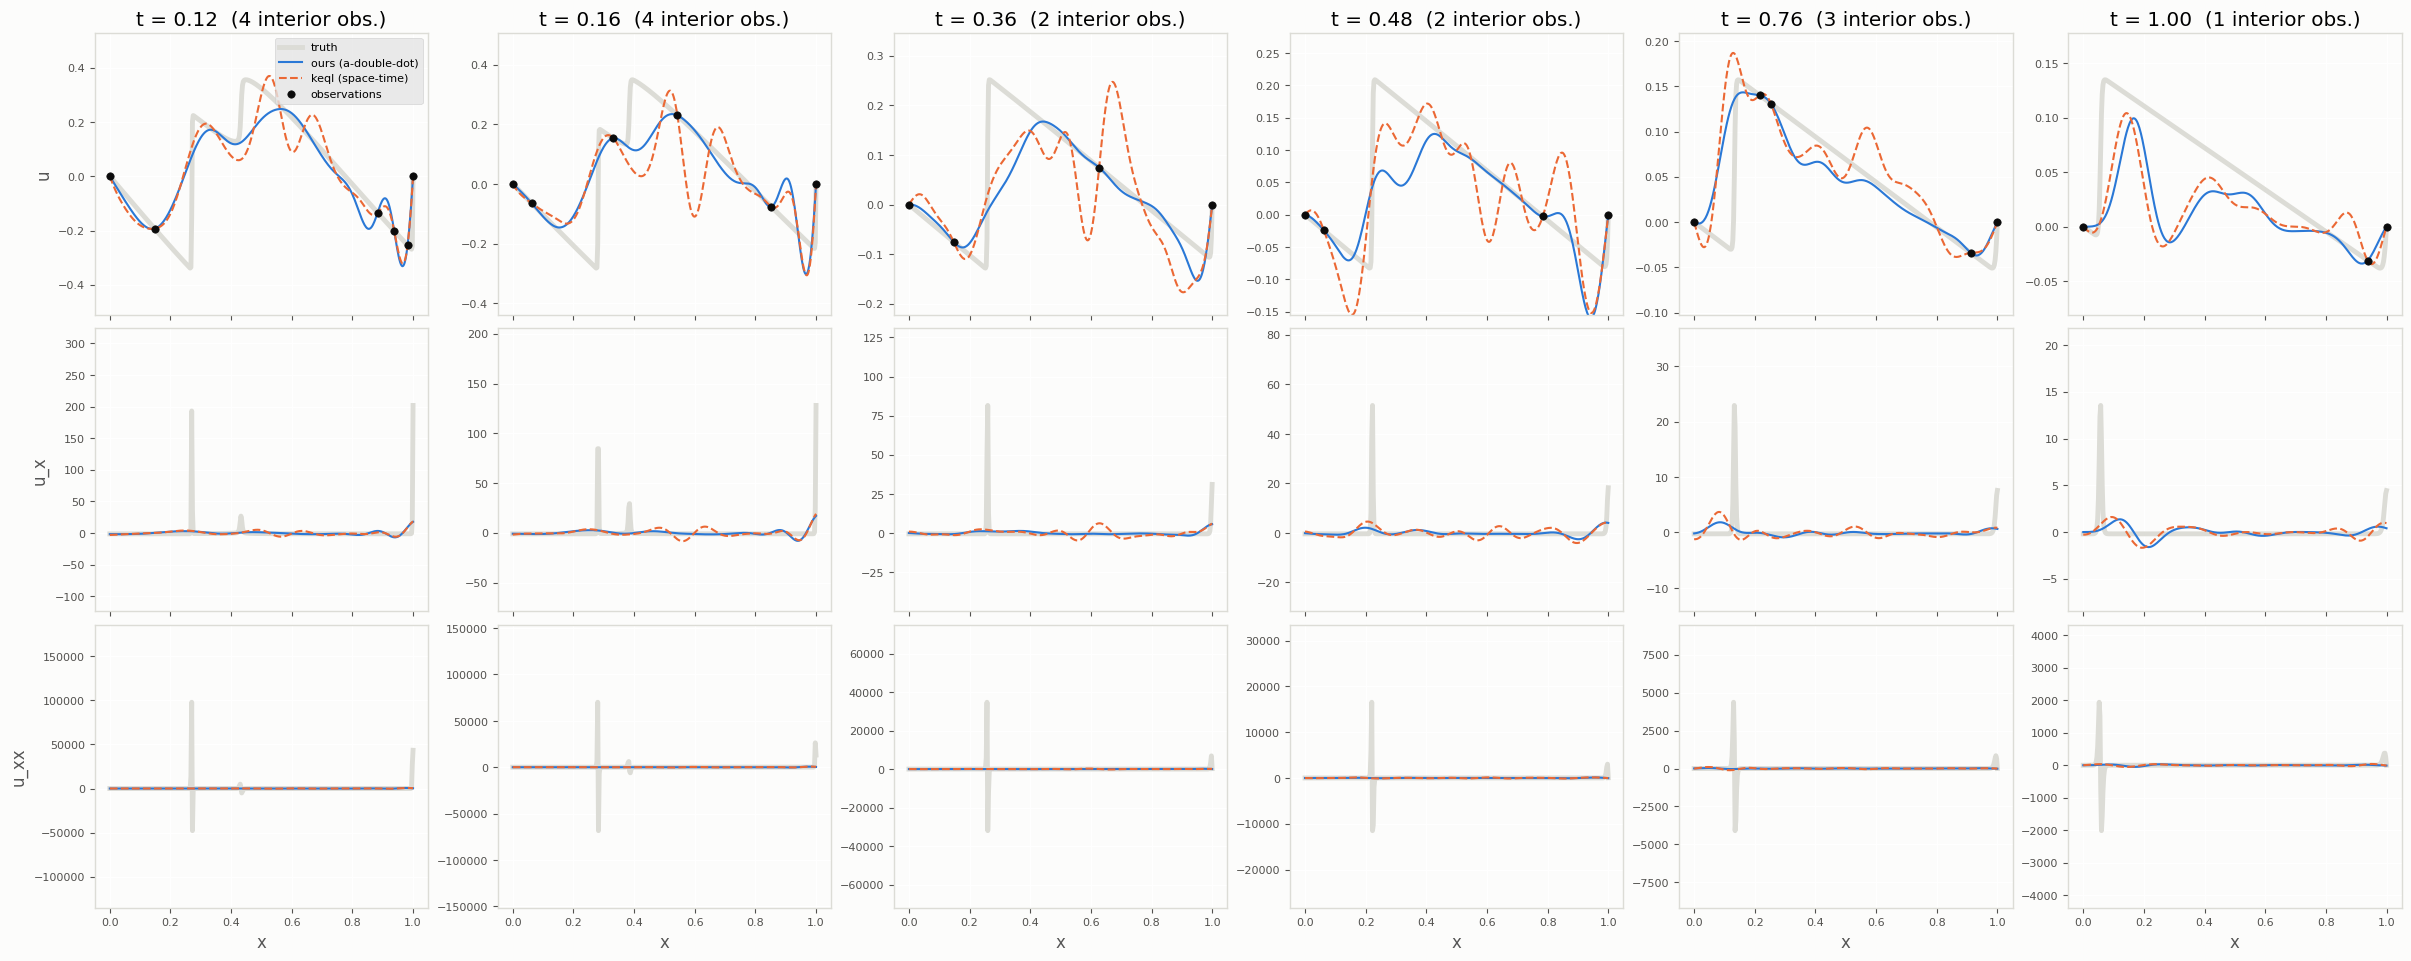

u_x and u_xx: colour scale and rel. L2 error exclude t = 0 (boundary kink of the reference solution); dots = observed nodes


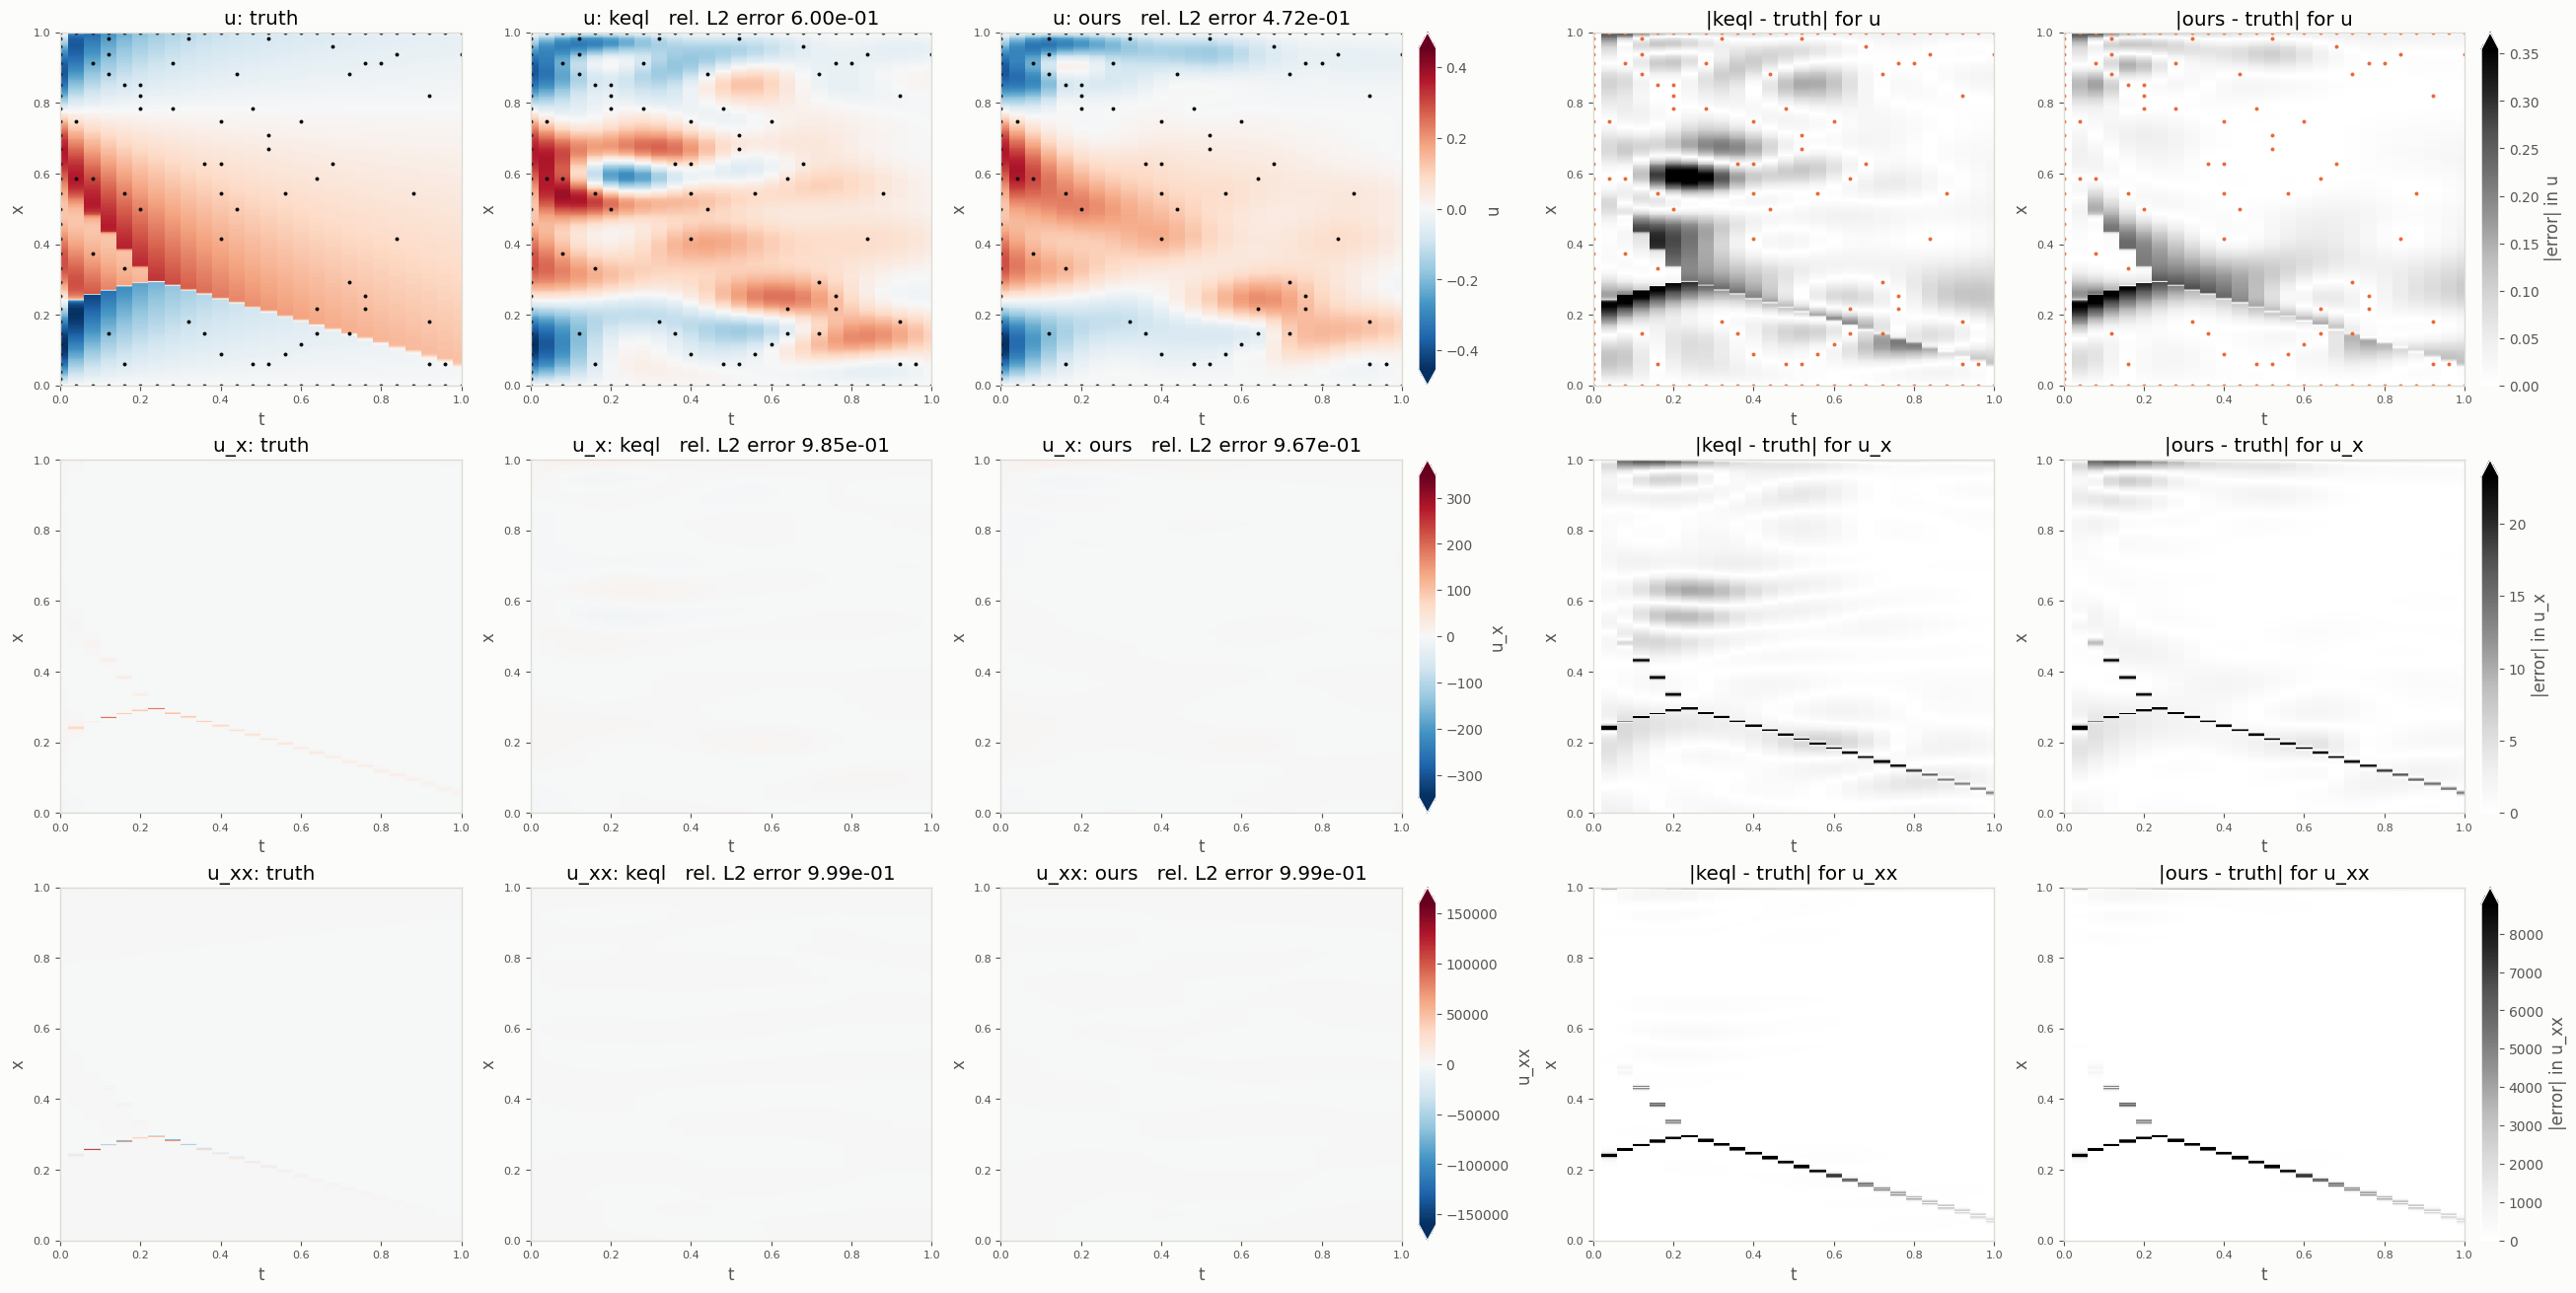

In [5]:
# =====================================================================================
# 2-step method, Step 1: state fit (our time-stepping version) with the a-double-dot time prior
# =====================================================================================
# All 26 columns are fitted together (space-only kernel; the columns are coupled only through the time prior):
#   {alpha_bar_n} = argmin  sum_{n=0}^{25} sum_{k in Omega_n} ( u_obs(t_n, x_k) - (K alpha_n)_k )^2
#                         + LAM_U     sum_{n=0}^{25} alpha_n^T K alpha_n
#                         + (LAM_ADDOT / dt^4) sum_{n=1}^{24} || alpha_{n+1} - 2 alpha_n + alpha_{n-1} ||_K^2
# The last term penalises the discrete acceleration u_tt (changes in the rate u_t), never the rate itself, so it smooths
# the state in time without shrinking Step 2's target. LAM_ADDOT = 0 gives back the per-column fit.
# LAM_U = 1e-6 is Kernel Equation Learning's get_fitted_params default (lam = 1e-6).
# Solved in whitened coordinates, as they do: with K + 1e-8 I = L L^T (their nugget_size = 1e-8) and alpha_n = L^{-T} w_n,
#   alpha_n^T K alpha_n ~ ||w_n||^2,  ||alpha_{n+1} - 2 alpha_n + alpha_{n-1}||_K^2 ~ ||w_{n+1} - 2 w_n + w_{n-1}||^2,
# so with w = (w_0, ..., w_25) stacked (806 entries) the whole fit is ONE ridge problem
#   w = argmin ||M_aug w - y_aug||^2 + LAM_U ||w||^2,
#   M_aug = [ M_all ; sqrt(LAM_ADDOT)/dt^2 (D_tt kron I_31) ],  y_aug = [ u_obs ; 0 ],
# M_all = observation rows (row i = (K L^{-T})[k_of[i]] in block n_of[i]),  D_tt (24, 26) = second difference in time,
# solved by SVD (same formula as their l2reg_lstsq, written out here).
# LAM_ADDOT is chosen from the data only: 5-fold CV on the 100 interior observations (boundary + IC observations always kept).
LAM_U = 1e-6
LAM_GRID = np.r_[0, np.logspace(-12, -1, 23)]                    # candidate LAM_ADDOT values (0 = per-column fit)
L_chol = np.linalg.cholesky(K + 1e-8 * np.eye(N_X))              # K + 1e-8 I = L L^T
LinvT = np.linalg.inv(L_chol).T                                  # alpha = L^{-T} w

def ridge_svd(M, y, reg):
    """argmin_w ||M w - y||^2 + reg ||w||^2 via the SVD of M."""
    U, s, Vt = np.linalg.svd(M, full_matrices=False)
    return Vt.T @ ((s / (s ** 2 + reg)) * (U.T @ y))

M_all = np.zeros((len(u_obs), N_X * N_T))                                       # (181, 806)
cols_of = n_of[:, None] * N_X + np.arange(N_X)[None, :]                         # column indices of each row's block
M_all[np.arange(len(u_obs))[:, None], cols_of] = K[k_of] @ LinvT
D_tt = (np.eye(N_T, k=2) - 2 * np.eye(N_T, k=1) + np.eye(N_T))[:-2]             # (24, 26): w_{n+1} - 2 w_n + w_{n-1}
R_tt = np.kron(D_tt, np.eye(N_X)) / DT ** 2                                     # (744, 806) time rows

def fit_state(lam, rows=None):
    """alpha (31, 26) from the observations in `rows` (default: all 181) with time-prior weight lam."""
    rows = np.arange(len(u_obs)) if rows is None else rows
    M_aug = np.vstack([M_all[rows], np.sqrt(lam) * R_tt])
    y_aug = np.r_[u_obs[rows], np.zeros(R_tt.shape[0])]
    return LinvT @ ridge_svd(M_aug, y_aug, LAM_U).reshape(N_T, N_X).T

# 5-fold CV: hold out a fifth of the interior observations, predict them, RMS error
folds = np.array_split(np.random.default_rng(0).permutation(np.where(is_int)[0]), 5)
def cv_rmse(lam):
    err = [(K @ fit_state(lam, np.setdiff1d(np.arange(len(u_obs)), f)))[k_of[f], n_of[f]] - u_obs[f] for f in folds]
    return np.sqrt(np.mean(np.concatenate(err) ** 2))
cv = np.array([cv_rmse(l) for l in LAM_GRID])
LAM_ADDOT = LAM_GRID[np.argmin(cv)]
print(f"LAM_ADDOT chosen by 5-fold CV: {LAM_ADDOT:.1e}  (CV error {cv.min():.2e}; per-column fit, LAM_ADDOT = 0: {cv[0]:.2e})")
alpha_bar = fit_state(LAM_ADDOT)                                  # (31, 26), column n = alpha_bar_n

# our state and features at the nodes
u_bar  = (K @ alpha_bar).T                                       # (26, 31) nodal values  u_bar_n = K alpha_bar_n
S_bar  = np.stack([(D0 @ alpha_bar).T, (D1 @ alpha_bar).T, (D2 @ alpha_bar).T], -1)   # (26, 29, 3): (u, u_x, u_xx)

# =====================================================================================
# Keql's Step 1 (their two-step state, errors_curves.ipynb lines 110-117):
# one space-time fit to all 181 observations, basis = (eval, d_x, d_t) functionals at all 806 collocation points.
# =====================================================================================
from EquationModel import CholInducedRKHS
from KernelTools import dt_k
u_model = CholInducedRKHS(jnp.vstack([tx_bdy, tx_int]), (eval_k, dx_k, dt_k), k_u_keql, nugget_size=1e-8)
u_params_keql = u_model.get_fitted_params(jnp.asarray(tx_obs), jnp.asarray(u_obs))      # lam = 1e-6

# their state and features at OUR nodes (their functions of (t, x) are defined everywhere)
nodes_int = np.stack([TT[:, 1:-1].ravel(), XX[:, 1:-1].ravel()], 1)                    # (754, 2), (n, k) order
u_keql = np.asarray(u_model.point_evaluate(jnp.asarray(nodes), u_params_keql)).reshape(N_T, N_X)
S_keql = np.asarray(u_model.evaluate_operators((eval_k, dx_k, dxx_k), jnp.asarray(nodes_int), u_params_keql)
                      ).reshape(3, N_T, N_X - 2).transpose(1, 2, 0)                     # (26, 29, 3)

# truth at the same nodes
S_true = np.stack([tru.u(t, x_int), tru.u_x(t, x_int), tru.u_xx(t, x_int)], -1)        # (26, 29, 3)
u_true_nodes = tru.u(t, x)

# =====================================================================================
# Checks and summary numbers
# =====================================================================================
# data misfit at the observations (not a pass/fail: both fits are regularised, so neither interpolates exactly)
print(f"max |fit - u_obs| at the 181 observations: ours {np.abs(u_bar[n_of, k_of] - u_obs).max():.1e}, "
      f"keql {np.abs(np.asarray(u_model.point_evaluate(jnp.asarray(tx_obs), u_params_keql)) - u_obs).max():.1e}")

def rel(err, ref):                                               # relative L2 error
    return np.linalg.norm(err) / np.linalg.norm(ref)

print(f"\nrelative L2 error at the nodes      {'ours':>10s} {'keql':>10s}")
print(f"  u    (806 nodes)                  {rel(u_bar - u_true_nodes, u_true_nodes):10.2e} "
      f"{rel(u_keql - u_true_nodes, u_true_nodes):10.2e}")
for i, name in enumerate(["u", "u_x", "u_xx"]):
    print(f"  {name:4s} features (754 interior)      {rel(S_bar[..., i] - S_true[..., i], S_true[..., i]):10.2e} "
          f"{rel(S_keql[..., i] - S_true[..., i], S_true[..., i]):10.2e}")

# Visualize state fit
# State fit, column by column: truth vs ours (all columns together, a-double-dot prior) vs keql (space-time fit) at selected time columns.
# Rows: u, u_x, u_xx (the operator's features) on a fine x grid; dots = observations in that column (u row only).
# Columns chosen to span sparse and rich columns (number of interior observations in the title).
cols = [3, 4, 9, 12, 19, 25]
xf = np.linspace(0, 1, 401)
B = {0: gram(k_state, xf, x), 1: gram(d1, xf, x), 2: gram(d2, xf, x)}        # our basis and its derivatives on xf
keql_ops = (eval_k, dx_k, dxx_k)
true_fns = (tru.u, tru.u_x, tru.u_xx)
names = ("u", "u_x", "u_xx")

fig, ax = plt.subplots(3, len(cols), figsize=(4 * len(cols), 9.5), facecolor=SURF, layout="constrained", sharex=True)
for j, n in enumerate(cols):
    P = jnp.stack([jnp.full(len(xf), t[n]), jnp.asarray(xf)], 1)               # (t_n, x) on the fine grid
    for i in range(3):
        a = ax[i, j]
        truth_f = true_fns[i](t[n], xf)[0]
        ours_f = B[i] @ alpha_bar[:, n]
        keql_f = np.asarray(u_model.evaluate_operators((keql_ops[i],), P, u_params_keql)).ravel()
        a.plot(xf, truth_f, lw=3.5, c=GRID, label="truth")
        a.plot(xf, ours_f, lw=1.5, c=C1, label="ours (a-double-dot)")
        a.plot(xf, keql_f, lw=1.5, c=C2, ls="--", label="keql (space-time)")
        if i == 0:
            m = n_of == n
            a.scatter(x[k_of[m]], u_obs[m], s=28, c=INK, zorder=4, label="observations")
            a.set_title(f"t = {t[n]:.2f}  ({np.sum(is_int & m)} interior obs.)")
            lo, hi = truth_f.min(), truth_f.max(); pad = .25 * (hi - lo)   # clip to the truth's scale
            a.set_ylim(lo - pad, hi + pad)
        else:
            lo, hi = truth_f.min(), truth_f.max(); pad = .6 * (hi - lo)
            a.set_ylim(lo - pad, hi + pad)
        if j == 0: a.set_ylabel(names[i])
        if i == 2: a.set_xlabel("x")
        style(a)
ax[0, 0].legend(fontsize=8, loc="upper right")
plt.show()

# Reconstructed fields: truth vs keql (space-time fit) vs "ours (a-double-dot)", for u, u_x, u_xx.
# All three are evaluated on the SAME points: the 26 time columns t_n x 401 points in x
# (ours only exists at the columns; keql and truth are sampled there so the maps are directly comparable).
# Columns of the figure: truth | keql | ours | |keql - truth| | |ours - truth|.  Rows: u, u_x, u_xx.
# Field panels in a row share the truth's colour range (values beyond it are saturated);
# error panels in a row share one scale.
xf = np.linspace(0, 1, 401)
B = {0: gram(k_state, xf, x), 1: gram(d1, xf, x), 2: gram(d2, xf, x)}    # our basis and derivatives on xf, (401, 31)
keql_ops = (eval_k, dx_k, dxx_k)
true_fns = (tru.u, tru.u_x, tru.u_xx)
names = ("u", "u_x", "u_xx")

fields = {"truth": [], "keql": [], "ours": []}                   # each entry: (26, 401)
for i in range(3):
    fields["truth"].append(true_fns[i](t, xf))
    fields["ours"].append((B[i] @ alpha_bar).T)
    # keql's space-time function evaluated column by column (keeps the kernel matrix small)
    fields["keql"].append(np.stack([
        np.asarray(u_model.evaluate_operators((keql_ops[i],),
                   jnp.stack([jnp.full(len(xf), t[n]), jnp.asarray(xf)], 1), u_params_keql)).ravel()
        for n in range(N_T)]))

te = np.r_[t[0] - .02, (t[1:] + t[:-1]) / 2, t[-1] + .02]        # time-cell edges around each column
hx = xf[1] - xf[0]; xfe = np.r_[xf - hx / 2, xf[-1] + hx / 2]   # x-cell edges around each fine point
fig, ax = plt.subplots(3, 5, figsize=(26, 13), facecolor=SURF, layout="constrained")
for i in range(3):
    F_true = fields["truth"][i]
    # derivatives: leave out t = 0 from colour scale and error (the reference solution's boundary kink sits there)
    lim = np.abs(F_true[1:] if i >= 1 else F_true).max()
    nrm = TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
    errs = {m: np.abs(fields[m][i] - F_true) for m in ("keql", "ours")}
    emax = max(np.percentile(errs["keql"][1:], 99.5), np.percentile(errs["ours"][1:], 99.5))
    for j, m in enumerate(("truth", "keql", "ours")):
        a = ax[i, j]
        F = fields[m][i]
        r = rel(F[1:] - F_true[1:], F_true[1:]) if i >= 1 else rel(F - F_true, F_true)
        im = a.pcolormesh(te, xfe, F.T, cmap="RdBu_r", norm=nrm, shading="flat")
        a.set(title=f"{names[i]}: {m}" + ("" if m == "truth" else f"   rel. L2 error {r:.2e}"),
              xlabel="t", ylabel="x", xlim=(0, 1), ylim=(0, 1))
        if i == 0:
            a.scatter(t[n_of], x[k_of], s=8, c=INK, lw=0)
    fig.colorbar(im, ax=ax[i, 2], fraction=.046, pad=.02, extend="both", label=names[i])
    for j, m in enumerate(("keql", "ours")):
        a = ax[i, 3 + j]
        im2 = a.pcolormesh(te, xfe, errs[m].T, cmap="Greys", vmin=0, vmax=emax, shading="flat")
        a.set(title=f"|{m} - truth| for {names[i]}", xlabel="t", ylabel="x", xlim=(0, 1), ylim=(0, 1))
        if i == 0:
            a.scatter(t[n_of], x[k_of], s=8, c=C2, lw=0)
    fig.colorbar(im2, ax=ax[i, 4], fraction=.046, pad=.02, extend="max", label=f"|error| in {names[i]}")
for a_ in ax.ravel(): style(a_)
print("u_x and u_xx: colour scale and rel. L2 error exclude t = 0 (boundary kink of the reference solution); dots = observed nodes")
plt.show()

Operator KMD library

[OK ] D3 vs finite difference of d2 (relative): 2.45e-08


[OK ] true operator = const + linear[u_xx] + linear[u*u_x] (relative): 1.81e-16
library: const + 6 features x 3 kernels = 19 atoms, 187 coefficients


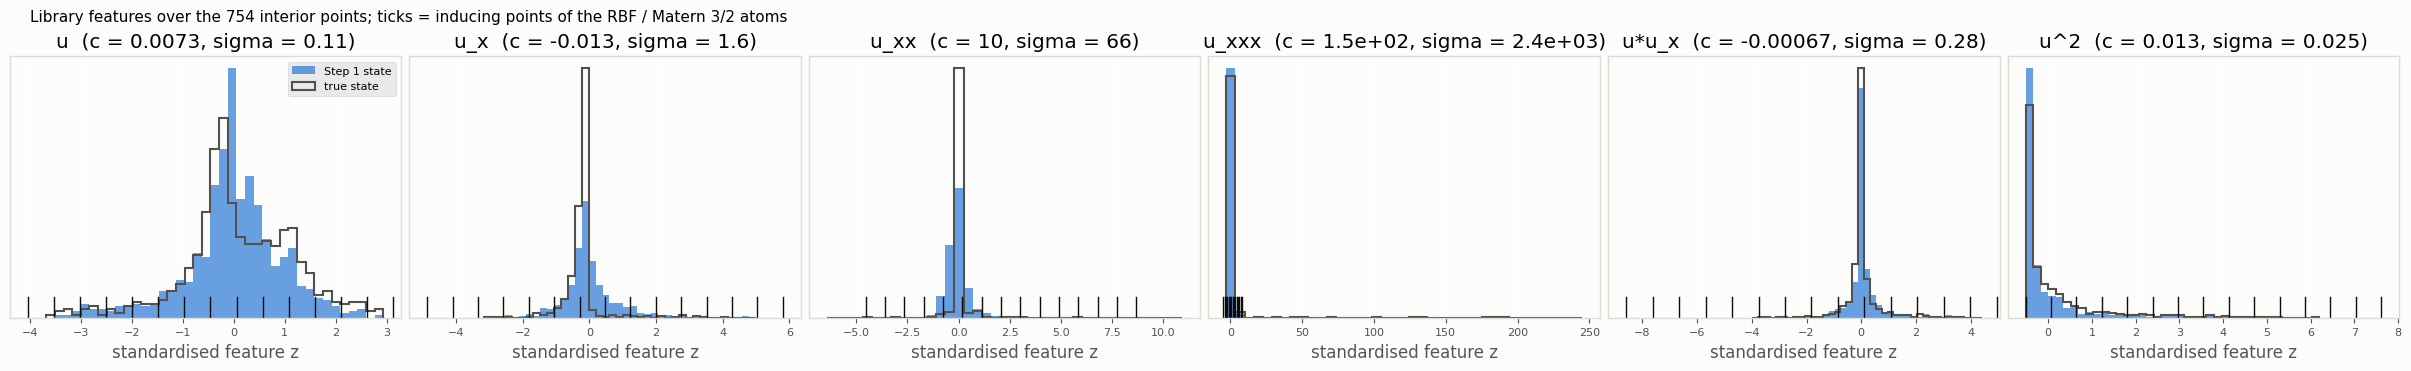

In [6]:
# =====================================================================================
# Operator KMD, part 1: the atom library (no fitting yet)
# =====================================================================================
# Features at the interior collocation points, from the state alpha_n:
#   s(x_k; alpha_n) = ((D0 alpha_n)_k, (D1 alpha_n)_k, (D2 alpha_n)_k, (D3 alpha_n)_k) = (u, u_x, u_xx, u_xxx),
#   D3 (29 x 31): (D3)_kl = d_xxx K(x, x_l)|_{x = x_k}  (new; D0, D1, D2 as before).
# Library features g(s) = (u, u_x, u_xx, u_xxx, u*u_x, u^2), each standardised by its mean c_i and standard deviation
#   sigma_i (ddof = 1) over the 754 interior points of the Step 1 state alpha_bar:  z_i = (g_i(s) - c_i) / sigma_i.
# Atoms m = (one feature i(m), one kernel k_m) acting on the scalar z_{i(m)}:
#   linear     k(z, z') = z z'                             -> 1 coefficient           (phi_m(z) = z)
#   rbf        k(z, z') = exp(-(z - z')^2 / 2)             -> J = 15 inducing points  (phi_m(z) = [k(z, zeta_mj)]_j)
#   matern32   k(z, z') = (1 + sqrt3 |z - z'|) exp(-sqrt3 |z - z'|)            "
#   inducing points zeta_mj = 15 evenly spaced values between the min and max of z_{i(m)} over the Step 1 points.
#   const      k = 1                                       -> 1 coefficient (P_hat's constant; never pruned)
# Operator:  P_hat(s) = sum_m phi_m(z_{i(m)})^T beta_m = Psi(s) b,   b = (beta_1, ..., beta_M) stacked.
# RKHS norm of atom m:  ||P_hat_m||^2 = beta_m^T K_m beta_m,  K_m = [k_m(zeta_mj, zeta_mj')]  (linear atom: K_m = 1).
# Everything is written in jax (works on numpy inputs too), so the hard variants can differentiate through it.
FEATURES = ["u", "u_x", "u_xx", "u_xxx", "u*u_x", "u^2"]
KERNELS = ["linear", "rbf", "matern32"]
J_IND = 15

d3 = jax.grad(d2, argnums=0)                                           # d^3/da^3 K(a, b)
D3 = gram(d3, x_int, x)                                                # (29, 31) -> u_xxx at interior nodes
D_all = [D0, D1, D2, D3]

def state_feats(al):
    """s(x_k; alpha_n) for all n, k:  al (31, N) -> (N, 29, 4) = (u, u_x, u_xx, u_xxx)."""
    return jnp.stack([(jnp.asarray(D) @ al).T for D in D_all], -1)

def lib_feats(S4):
    """Library features g(s): (..., 4) -> (..., 6) = (u, u_x, u_xx, u_xxx, u u_x, u^2)."""
    u, ux, uxx, uxxx = S4[..., 0], S4[..., 1], S4[..., 2], S4[..., 3]
    return jnp.stack([u, ux, uxx, uxxx, u * ux, u ** 2], -1)

def k_atom(kind, z, zeta):                                             # scalar kernel, broadcasting z (...,1) vs zeta (J,)
    if kind == "rbf":
        return jnp.exp(-0.5 * (z - zeta) ** 2)
    r = jnp.sqrt(3.0) * jnp.sqrt((z - zeta) ** 2 + 1e-30)              # matern32 (the 1e-30 keeps the gradient finite at r = 0)
    return (1 + r) * jnp.exp(-r)

# ---- standardisation and inducing points from the Step 1 state
G_bar = np.asarray(lib_feats(state_feats(alpha_bar)))                  # (26, 29, 6)
c_lib = G_bar.reshape(-1, 6).mean(0)
sig_lib = G_bar.reshape(-1, 6).std(0, ddof=1)
Z_bar = (G_bar.reshape(-1, 6) - c_lib) / sig_lib                       # (754, 6) standardised Step 1 features
ZETA = [np.linspace(Z_bar[:, i].min(), Z_bar[:, i].max(), J_IND) for i in range(6)]   # inducing points per feature

ATOMS = [dict(i=None, kind="const", zeta=None, name="const", nb=1)]   # list of dicts: feature index, kernel, inducing points
for kind in KERNELS:
    for i, f in enumerate(FEATURES):
        zeta = None if kind == "linear" else ZETA[i]
        ATOMS.append(dict(i=i, kind=kind, zeta=zeta, name=f"{kind}[{f}]", nb=1 if kind == "linear" else J_IND))
M_ATOMS = len(ATOMS)
B_SLICE = np.cumsum([0] + [a["nb"] for a in ATOMS])                    # beta_m = b[B_SLICE[m]:B_SLICE[m+1]]
NB = B_SLICE[-1]
ATOM_ID = {a["name"]: m for m, a in enumerate(ATOMS)}
K_ATOM = [np.ones((1, 1)) if a["kind"] in ("const", "linear")
          else np.asarray(k_atom(a["kind"], a["zeta"][:, None], a["zeta"][None, :])) for a in ATOMS]
KREG = np.zeros((NB, NB))                                              # block-diagonal: sum_m beta_m^T K_m beta_m = b^T KREG b
for m in range(M_ATOMS):
    sl = slice(B_SLICE[m], B_SLICE[m + 1]); KREG[sl, sl] = K_ATOM[m]

def Psi(S4, atoms=None):
    """Design matrix of P_hat:  S4 (..., 4) raw features -> (..., NB), columns of atoms outside `atoms` set to 0.
    P_hat(s) = Psi(s) @ b.  `atoms`: list of active atom indices (default: all)."""
    Z = (lib_feats(S4) - c_lib) / sig_lib
    cols = []
    for m, a in enumerate(ATOMS):
        if a["kind"] == "const":
            blk = jnp.ones_like(Z[..., :1])
        else:
            z = Z[..., a["i"]][..., None]
            blk = z if a["kind"] == "linear" else k_atom(a["kind"], z, jnp.asarray(a["zeta"]))
        cols.append(blk if (atoms is None or m in atoms) else jnp.zeros_like(blk))
    return jnp.concatenate(cols, -1)

# ---- checks
h = 1e-5                                                               # D3 vs a centred difference of D2's kernel
D3_fd = (gram(d2, x_int + h, x) - gram(d2, x_int - h, x)) / (2 * h)
check("D3 vs finite difference of d2 (relative)", np.abs(D3 - D3_fd).max() / np.abs(D3).max(), tol=1e-5)
lin = [ATOM_ID["const"], ATOM_ID["linear[u_xx]"], ATOM_ID["linear[u*u_x]"]]   # the true operator = const + 2 linear atoms
b_true_lib = np.zeros(NB)                                             # (z = (g - c) / sigma  ->  g = sigma z + c)
b_true_lib[B_SLICE[lin[0]]] = KAPPA * c_lib[2] + ALPHA * c_lib[4]
b_true_lib[B_SLICE[lin[1]]] = KAPPA * sig_lib[2]; b_true_lib[B_SLICE[lin[2]]] = ALPHA * sig_lib[4]
# true u_xxx: the reference spline is cubic (no 3rd derivative), so differentiate keql's solver solution (2001 points)
# three times by centred differences at the solver time closest to each t_n, then interpolate to x_int
it_n = np.array([np.argmin(np.abs(t_solver - tn)) for tn in t])
uxxx_sol = np.gradient(np.gradient(np.gradient(sols[it_n], x_solver, axis=1), x_solver, axis=1), x_solver, axis=1)
uxxx_true = np.stack([np.interp(x_int, x_solver, row) for row in uxxx_sol])          # (26, 29)
S4_true = np.concatenate([S_true, uxxx_true[..., None]], -1)           # true (u, u_x, u_xx, u_xxx) at the interior nodes
P_lin = np.asarray(Psi(S4_true, lin) @ b_true_lib)
check("true operator = const + linear[u_xx] + linear[u*u_x] (relative)",
      np.abs(P_lin - P_true(S_true)).max() / np.abs(P_true(S_true)).max(), tol=1e-10)
print(f"library: const + {len(FEATURES)} features x {len(KERNELS)} kernels = {M_ATOMS} atoms, {NB} coefficients")

# =====================================================================================
# Visual check: each library feature at the Step 1 state (standardised, histogram over the 754 points) vs the same
# feature at the TRUE state (grey outline), with the 15 inducing points of its stationary atoms (ticks).
# =====================================================================================
Z_true = (np.asarray(lib_feats(S4_true)).reshape(-1, 6) - c_lib) / sig_lib
fig, ax = plt.subplots(1, 6, figsize=(24, 3.6), facecolor=SURF, layout="constrained")
for i, f in enumerate(FEATURES):
    a = ax[i]
    lo, hi = np.percentile(np.r_[Z_bar[:, i], Z_true[:, i]], [0.5, 99.5])
    bins = np.linspace(lo, hi, 40)
    a.hist(Z_bar[:, i], bins=bins, color=C1, alpha=.7, label="Step 1 state")
    a.hist(Z_true[:, i], bins=bins, histtype="step", color=MUTED, lw=1.5, label="true state")
    for zz in ZETA[i]:
        a.axvline(zz, ymax=.08, c=INK, lw=1)
    a.set(title=f"{f}  (c = {c_lib[i]:.2g}, sigma = {sig_lib[i]:.2g})", xlabel="standardised feature z", yticks=[])
    style(a)
ax[0].legend(fontsize=8)
fig.suptitle("Library features over the 754 interior points; ticks = inducing points of the RBF / Matern 3/2 atoms",
             x=0.01, ha="left", fontsize=11)
plt.show()

Operator fit

backward elimination: min CV 2.392e-02 +- 6.3e-03 at 2 atoms; 1-SE rule -> 1 atoms (CV 2.444e-02, lambda_beta 1e-12): linear[u]


[OK ] K_op: psi psi^T vs keql kernel (relative): 1.71e-16
e at the truth (rel. to K(alpha_(n+1) - alpha_n)): 0.861


[BAD] true operator on the eval grid (spline consistency): 1.97e-01


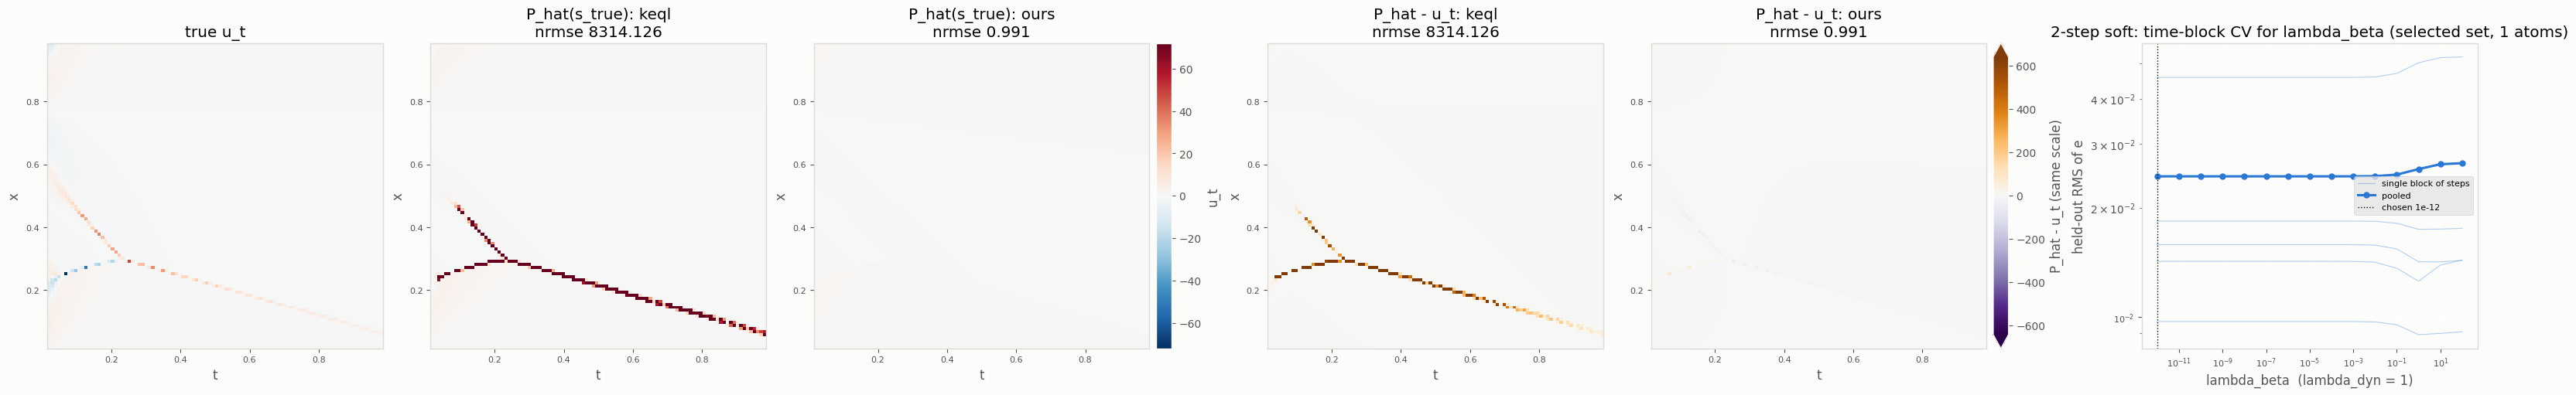

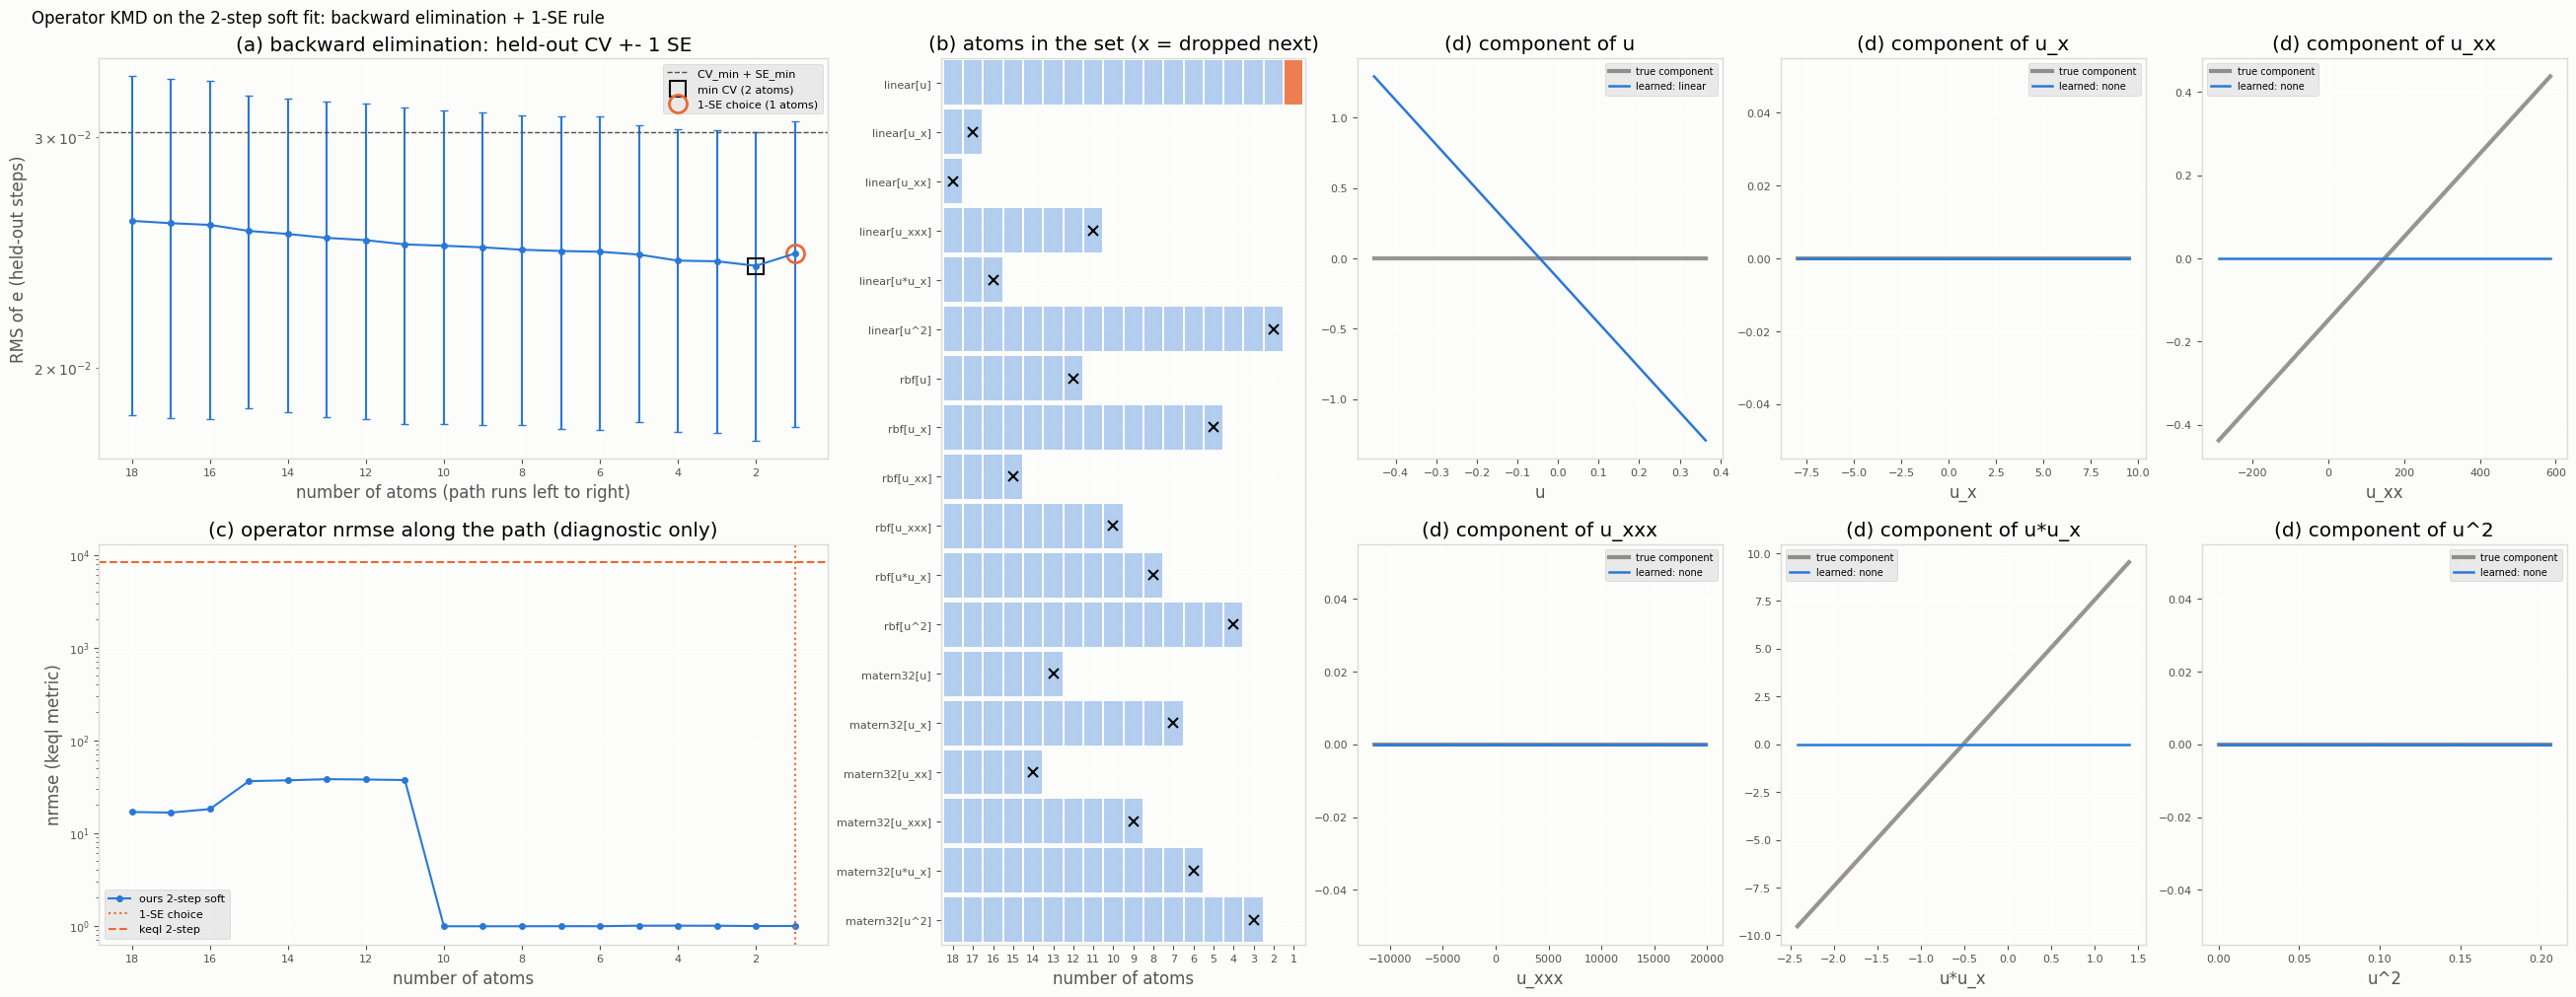

In [7]:
# =====================================================================================
# 2-step method, Step 2: operator fit on the frozen Step 1 state (soft constraint)
# =====================================================================================
# Operator: the KMD library (previous cell),  P_hat(s) = Psi(s) b = sum over active atoms m of phi_m(z_{i(m)})^T beta_m,
#   s = (u, u_x, u_xx, u_xxx).  keql's degree-2 kernel psi(s) on (u, u_x, u_xx) is kept below only for keql's fit,
#   the K_op check and the keql rollout.
#
# Dynamic residual (note p.3), theta_n = THETA = 1/2 (Crank-Nicolson), all 31 rows:
#   e(alpha_{n+1}; b) = K (alpha_{n+1} - alpha_n) - dt [ theta_n r(alpha_{n+1}; b) + (1 - theta_n) r(alpha_n; b) ],  n = 0..24,
#   r(alpha_n; b) = [0; P_hat(s(x_k; alpha_n)), k = 1..29; 0].
# Loss (note p.6, state frozen at alpha_bar, active atom set A):
#   J(b) = lambda_dyn sum_{n=0}^{24} || e(alpha_bar_{n+1}; b) ||^2 + lambda_beta sum_{m in A} beta_m^T K_m beta_m.
# e(alpha_bar_{n+1}; b) is linear in b. Boundary rows k = 0, 30 have no b -> drop out.
#   Interior rows: e_n = d_n - A_n b,  d_n = (K alpha_bar_{n+1} - K alpha_bar_n)_{1:29},
#   A_n = dt [ theta Psi(s_{n+1}) + (1 - theta) Psi(s_n) ]  (columns of the active atoms only),  so
#   b = ( lambda_dyn sum_n A_n^T A_n + lambda_beta KREG_A )^{-1} lambda_dyn sum_n A_n^T d_n.
# Weights: LAM_DYN_2S = 1; lambda_beta by 5-fold CV over blocks of time steps (score: RMS of e on the held-out steps).
# Atom selection (KMD) by backward elimination with time-block CV:
#   start from all atoms; at each step, for every non-constant atom m in the active set A, CV the set A \ {m}
#   (lambda_beta re-chosen by CV for each candidate set) and drop the atom whose removal gives the lowest CV;
#   continue down to one non-constant atom (the constant atom is always kept).  This gives a path of nested sets.
# One-standard-error rule on that path: CV_min = lowest pooled CV on the path, SE_min = std of its 5 fold errors / sqrt(5);
#   select the set with the FEWEST atoms whose pooled CV <= CV_min + SE_min.
from Kernels import get_centered_scaled_poly_kernel
from EquationModel import OperatorModel
from KernelTools import vectorize_kfunc

THETA = 0.5                                                            # theta_n: 1/2 = Crank-Nicolson, 1 = backward Euler
LAM_DYN_2S = 1.0                                                       # lambda_dyn (reference)

# keql's degree-2 feature map: kept only for keql's fit, the K_op check and the keql rollout
def psi(S, c, sig):
    """Explicit feature map of keql's degree-2 kernel.  S: (..., 3) raw features -> (..., 10)."""
    z = (S - c) / sig
    z1, z2, z3 = z[..., 0], z[..., 1], z[..., 2]
    r2 = np.sqrt(2.0)
    return np.stack([np.ones_like(z1), r2 * z1, r2 * z2, r2 * z3, z1 ** 2, z2 ** 2, z3 ** 2,
                     r2 * z1 * z2, r2 * z1 * z3, r2 * z2 * z3], -1)

def scaling(S):
    """c and sigma (ddof = 1) over all interior feature points, as keql's get_centered_scaled_poly_kernel does."""
    return S.reshape(-1, 3).mean(0), S.reshape(-1, 3).std(0, ddof=1)

LAM_BETA_2S_GRID = np.logspace(-12, 2, 15)                             # lambda_beta candidates

# ---- design for the frozen Step 1 state
S4_bar = np.asarray(state_feats(alpha_bar))                            # (26, 29, 4): s(x_k; alpha_bar_n)
Psi_bar = np.asarray(Psi(S4_bar))                                      # (26, 29, NB): all atoms
d_bar = u_bar[1:, 1:-1] - u_bar[:-1, 1:-1]                             # (25, 29): (K alpha_bar_{n+1} - K alpha_bar_n)_k
A_bar = DT * (THETA * Psi_bar[1:] + (1 - THETA) * Psi_bar[:-1])        # (25, 29, NB): dt [theta Psi_{n+1} + (1 - theta) Psi_n]
cols_of = lambda atoms: np.concatenate([np.arange(B_SLICE[m], B_SLICE[m + 1]) for m in atoms])

def fit_b(atoms, lam_beta, steps=None):
    """Closed-form minimiser of J(b) over the active atoms, using only the steps n in `steps` (default: all 25)."""
    steps = np.arange(N_T - 1) if steps is None else np.asarray(steps)
    cols = cols_of(atoms)
    A_, d_ = A_bar[steps][..., cols].reshape(-1, len(cols)), d_bar[steps].ravel()
    H = LAM_DYN_2S * A_.T @ A_ + lam_beta * KREG[np.ix_(cols, cols)]
    b = np.zeros(NB)
    b[cols] = np.linalg.solve(H + 1e-12 * np.trace(H) / len(cols) * np.eye(len(cols)), LAM_DYN_2S * A_.T @ d_)
    return b

s_blocks = np.array_split(np.arange(N_T - 1), 5)                       # steps n = 0..24 in 5 blocks of 5
def cv_beta_2s(atoms, lam_beta):
    res = []
    for blk in s_blocks:
        b = fit_b(atoms, lam_beta, steps=np.setdiff1d(np.arange(N_T - 1), blk))
        res.append((d_bar[blk] - A_bar[blk] @ b).ravel())
    return np.array([np.sqrt(np.mean(r ** 2)) for r in res]), np.sqrt(np.mean(np.concatenate(res) ** 2))

# ---- keql's metric grid with true features, incl. u_xxx (needed below for P_hat at the true features)
g_ev = np.linspace(0, 1, 104)[2:-2]
S_eval = np.stack([tru.u(g_ev, g_ev), tru.u_x(g_ev, g_ev), tru.u_xx(g_ev, g_ev)], -1).reshape(-1, 3)   # (10000, 3), t-major
it_ev = np.array([np.argmin(np.abs(t_solver - tt)) for tt in g_ev])    # true u_xxx: centred differences of the solver solution
uxxx_ev = np.gradient(np.gradient(np.gradient(sols[it_ev], x_solver, axis=1), x_solver, axis=1), x_solver, axis=1)
S4_eval = np.c_[S_eval, np.stack([np.interp(g_ev, x_solver, row) for row in uxxx_ev]).ravel()]          # (10000, 4)
ut_eval = tru.u_t(g_ev, g_ev).ravel()
nrmse = lambda pred: np.sqrt(np.mean((pred - ut_eval) ** 2) / np.mean(ut_eval ** 2))
Psi_eval = np.asarray(Psi(S4_eval))                                    # (10000, NB)

def cv_set(atoms):
    """Time-block CV of an atom set, lambda_beta chosen by CV: pooled CV, its standard error, lambda_beta, CV curves."""
    res = [cv_beta_2s(atoms, l) for l in LAM_BETA_2S_GRID]
    cvf, cvp = np.array([r[0] for r in res]), np.array([r[1] for r in res])
    k = int(np.argmin(cvp))
    return dict(cv=cvp[k], se=cvf[k].std(ddof=1) / np.sqrt(len(s_blocks)), lam=LAM_BETA_2S_GRID[k], cv_curve=cvp, cv_fold=cvf)

# ---- backward elimination path
A, PATH = list(range(M_ATOMS)), []
while True:
    PATH.append(dict(atoms=list(A), dropped=None, **cv_set(A)))
    nonc = [m for m in A if ATOMS[m]["kind"] != "const"]
    if len(nonc) == 1:
        break
    cand = [(cv_set([a for a in A if a != m])["cv"], m) for m in nonc]     # CV of A without m, for each m
    m_out = min(cand)[1]
    PATH[-1]["dropped"] = m_out
    A.remove(m_out)
for st in PATH:                                                        # operator error along the path (diagnostic only)
    st["op"] = nrmse(Psi_eval @ fit_b(st["atoms"], st["lam"]))

# ---- one-standard-error rule
i_min = int(np.argmin([st["cv"] for st in PATH]))
CV_THR = PATH[i_min]["cv"] + PATH[i_min]["se"]
i_sel = max(i for i, st in enumerate(PATH) if st["cv"] <= CV_THR)    # later on the path = fewer atoms
SEL = PATH[i_sel]
ACTIVE, LAM_BETA_2S, cv2, cv2_fold = SEL["atoms"], SEL["lam"], SEL["cv_curve"], SEL["cv_fold"]
b_2s = fit_b(ACTIVE, LAM_BETA_2S)
n_at = lambda st: len(st["atoms"]) - 1                                 # number of non-constant atoms
print(f"backward elimination: min CV {PATH[i_min]['cv']:.3e} +- {PATH[i_min]['se']:.1e} at {n_at(PATH[i_min])} atoms; "
      f"1-SE rule -> {n_at(SEL)} atoms (CV {SEL['cv']:.3e}, lambda_beta {LAM_BETA_2S:.0e}): "
      + ", ".join(ATOMS[m]["name"] for m in ACTIVE if ATOMS[m]["kind"] != "const"))

# ---- ours: Step 1 state, selected atoms
P_hat_ours = lambda S4: np.asarray(Psi(S4, ACTIVE)) @ b_2s

c_bar, sig_bar = scaling(S_bar)                                         # keql's psi scaling (keql fit, K_op check, keql rollout)

# ---- check: psi psi^T equals keql's kernel function (same points -> same c, sigma)
k_op_check = vectorize_kfunc(get_centered_scaled_poly_kernel(2, jnp.asarray(S_bar.reshape(-1, 3)), c=1., scaling="diagonal"))
S_test = S_bar.reshape(-1, 3)[::37]
Kop_keql_fn = np.asarray(k_op_check(jnp.asarray(S_test), jnp.asarray(S_test)))
check("K_op: psi psi^T vs keql kernel (relative)",
      np.abs(psi(S_test, c_bar, sig_bar) @ psi(S_test, c_bar, sig_bar).T - Kop_keql_fn).max() / np.abs(Kop_keql_fn).max())

# ---- check: e at the TRUE state and TRUE operator (0.01 u_xx + u u_x), relative to K(alpha_{n+1} - alpha_n):
#      the Crank-Nicolson truncation error (-dt^3/12 u_ttt), i.e. the floor of the dynamic residual
d_tr = u_true_nodes[1:, 1:-1] - u_true_nodes[:-1, 1:-1]
P_tr = P_true(S_true)           # (26, 29)
print(f"e at the truth (rel. to K(alpha_(n+1) - alpha_n)): {rel(d_tr - DT * (THETA * P_tr[1:] + (1 - THETA) * P_tr[:-1]), d_tr):.3f}")

# =====================================================================================
# keql's Step 2 (paper eq. 13): kernel regression of u_t of their Step 1 state at the 754 tx_int points.
# Features are (t, x, u, u_x, u_xx); the operator kernel only sees the last three (x[2:]), as in their code.
# Target = d_t of their space-time state (their twostep script fits a zero right-hand side; eq. 13 uses u_t).
# =====================================================================================
k_P_u_part = get_centered_scaled_poly_kernel(2, jnp.asarray(S_keql.reshape(-1, 3)), c=1., scaling="diagonal")
@vectorize_kfunc
def k_P(a, b_):
    return k_P_u_part(a[2:], b_[2:])
P_model = OperatorModel(k_P)
anchors_keql = jnp.hstack([jnp.asarray(nodes_int), jnp.asarray(S_keql.reshape(-1, 3))])        # (754, 5)
ut_keql = np.asarray(u_model.evaluate_operators((dt_k,), jnp.asarray(nodes_int), u_params_keql)).ravel()
beta_keql = P_model.fit_params(anchors_keql, jnp.asarray(ut_keql), nugget=1e-8)               # (K_op + 1e-8 diag) beta = u_t
def P_hat_keql(S):
    Sfull = jnp.hstack([jnp.zeros((S.shape[0], 2)), jnp.asarray(S)])  # (t, x) slots are ignored by k_P
    return np.asarray(P_model.predict_new(Sfull, anchors_keql, beta_keql))

# Note: keql's eq. 13 collocates u_t = P_hat at the points (their u_t = d_t of a space-time function); ours enforces the
# CN step between columns. Their nugget 1e-8 * diag(K_op) also weights points by 1 / ||psi(s_p)||^2.

# =====================================================================================
# keql's operator-error metric (errors_curves.ipynb): 100 x 100 grid linspace(0,1,104)[2:-2] in (t, x),
# true features from the spline, target = true u_t,  nrmse = sqrt(mean (P_hat - u_t)^2 / mean u_t^2)  (not squared).
# =====================================================================================
# (g_ev, S_eval, S4_eval, ut_eval, nrmse defined above, before the pruning rounds)
P_eval = {"ours": P_hat_ours(S4_eval), "keql": P_hat_keql(S_eval)}
check("true operator on the eval grid (spline consistency)",
      nrmse(P_true(S_eval)), tol=1e-4)

# =====================================================================================
# Visual check on keql's metric grid (100 x 100 in (t, x)), both operators evaluated at the TRUE features.
# Columns: true u_t | keql P_hat | ours P_hat | keql P_hat - u_t | ours P_hat - u_t | CV curve for lambda_beta.
# Field panels share the true u_t colour range; the two (signed) error panels share one symmetric range.
# =====================================================================================
ne = len(g_ev)
edges = np.r_[g_ev - (g_ev[1] - g_ev[0]) / 2, g_ev[-1] + (g_ev[1] - g_ev[0]) / 2]   # cell edges of the eval grid
F = {"true u_t": ut_eval, "keql": P_eval["keql"], "ours": P_eval["ours"]}
lim = np.abs(ut_eval).max()
err = {m: P_eval[m] - ut_eval for m in ("keql", "ours")}
elim = max(np.percentile(np.abs(e), 99.5) for e in err.values())

fig, ax = plt.subplots(1, 6, figsize=(32, 5), facecolor=SURF, layout="constrained")
for j, (m, v) in enumerate(F.items()):
    im = ax[j].pcolormesh(edges, edges, v.reshape(ne, ne).T, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim), shading="flat")
    ax[j].set_title(m if j == 0 else f"P_hat(s_true): {m}\nnrmse {nrmse(v):.3f}")
fig.colorbar(im, ax=ax[2], fraction=.046, pad=.02, label="u_t")
for j, m in enumerate(("keql", "ours"), start=3):
    im2 = ax[j].pcolormesh(edges, edges, err[m].reshape(ne, ne).T, cmap="PuOr_r",
                           norm=TwoSlopeNorm(0, -elim, elim), shading="flat")
    ax[j].set_title(f"P_hat - u_t: {m}\nnrmse {nrmse(P_eval[m]):.3f}")
fig.colorbar(im2, ax=ax[4], fraction=.046, pad=.02, extend="both", label="P_hat - u_t (same scale)")
for a in ax[:5]:
    a.set(xlabel="t", ylabel="x")
a = ax[5]                                                               # CV for lambda_beta
for j in range(len(s_blocks)):
    a.loglog(LAM_BETA_2S_GRID, cv2_fold[:, j], "-", c=C1, lw=.8, alpha=.35, label="single block of steps" if j == 0 else None)
a.loglog(LAM_BETA_2S_GRID, cv2, "o-", c=C1, lw=2.2, ms=5, label="pooled")
a.axvline(LAM_BETA_2S, c=INK, lw=1, ls=":", label=f"chosen {LAM_BETA_2S:.0e}")
a.set(title=f"2-step soft: time-block CV for lambda_beta (selected set, {len(ACTIVE) - 1} atoms)", xlabel="lambda_beta  (lambda_dyn = 1)",
      ylabel="held-out RMS of e")
a.legend(fontsize=8)
for a in ax: style(a)
plt.show()

# =====================================================================================
# Visual check of the atom selection.
# (a) pooled CV +- 1 SE (5 time blocks) along the backward-elimination path vs the number of atoms; dashed = CV_min + SE_min;
#     marked: min CV and the 1-SE choice.
# (b) which atoms are in the set at each step (filled; orange = selected set), and the atom dropped at that step (x).
# (c) operator error on keql's metric grid along the path (truth-based diagnostic, NOT used for the selection).
# (d) the learned additive component of each feature (sum over selected atoms on that feature of phi_m(z) beta_m) vs the
#     feature value over the Step 1 points, and the true component (KAPPA u_xx, ALPHA u u_x, 0 otherwise), both centred
#     (the constant atom absorbs the means).
# =====================================================================================
nonconst = [m for m in range(M_ATOMS) if ATOMS[m]["kind"] != "const"]
na = np.array([n_at(st) for st in PATH])
fig = plt.figure(figsize=(26, 10), facecolor=SURF, layout="constrained")
gs = fig.add_gridspec(2, 6)
a = fig.add_subplot(gs[0, 0:2])
a.errorbar(na, [st["cv"] for st in PATH], yerr=[st["se"] for st in PATH], fmt="o-", c=C1, ms=4, capsize=3)
a.axhline(CV_THR, c=MUTED, ls="--", lw=1, label="CV_min + SE_min")
a.plot(na[i_min], PATH[i_min]["cv"], "s", ms=11, mfc="none", mec=INK, mew=1.5, label=f"min CV ({na[i_min]} atoms)")
a.plot(na[i_sel], SEL["cv"], "o", ms=13, mfc="none", mec=C2, mew=2, label=f"1-SE choice ({na[i_sel]} atoms)")
a.invert_xaxis(); a.set_yscale("log"); a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
a.set(title="(a) backward elimination: held-out CV +- 1 SE", xlabel="number of atoms (path runs left to right)",
      ylabel="RMS of e (held-out steps)"); a.legend(fontsize=8); style(a)
a = fig.add_subplot(gs[1, 0:2])
a.semilogy(na, [st["op"] for st in PATH], "o-", c=C1, ms=4, label="ours 2-step soft")
a.axvline(na[i_sel], c=C2, lw=1.5, ls=":", label="1-SE choice")
a.axhline(nrmse(P_eval["keql"]), c=C2, ls="--", label="keql 2-step")
a.invert_xaxis(); a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
a.set(title="(c) operator nrmse along the path (diagnostic only)", xlabel="number of atoms", ylabel="nrmse (keql metric)")
a.legend(fontsize=8); style(a)
a = fig.add_subplot(gs[:, 2])
for c_, st in enumerate(PATH):
    for row, m in enumerate(nonconst):
        if m in st["atoms"]:
            a.add_patch(plt.Rectangle((c_ - .45, row - .45), .9, .9, color=C2 if c_ == i_sel else C1,
                                      alpha=.85 if c_ == i_sel else .35, lw=0))
        if st["dropped"] == m:
            a.plot(c_, row, "x", c=INK, ms=7, mew=1.5)
a.set_xlim(-.6, len(PATH) - .4); a.set_ylim(len(nonconst) - .5, -.5)
a.set_yticks(range(len(nonconst)), [ATOMS[m]["name"] for m in nonconst], fontsize=8)
a.set_xticks(range(len(PATH)), na, fontsize=7)
a.set(title="(b) atoms in the set (x = dropped next)", xlabel="number of atoms"); style(a)
TRUE_COMP = {2: KAPPA, 4: ALPHA}                                       # true operator: KAPPA * u_xx + ALPHA * u u_x
G_flat = G_bar.reshape(-1, 6)
for i, fname in enumerate(FEATURES):
    a = fig.add_subplot(gs[i // 3, 3 + i % 3])
    gg = np.linspace(G_flat[:, i].min(), G_flat[:, i].max(), 200)
    z = (gg - c_lib[i]) / sig_lib[i]
    comp = np.zeros_like(gg)
    on = [m for m in ACTIVE if ATOMS[m]["i"] == i]
    for m in on:
        bm = b_2s[B_SLICE[m]:B_SLICE[m + 1]]
        comp += (z * bm[0]) if ATOMS[m]["kind"] == "linear" else np.asarray(k_atom(ATOMS[m]["kind"], z[:, None], jnp.asarray(ATOMS[m]["zeta"]))) @ bm
    tr = TRUE_COMP.get(i, 0.0) * gg
    a.plot(gg, tr - tr.mean(), c=MUTED, lw=3, alpha=.6, label="true component")
    a.plot(gg, comp - comp.mean(), c=C1, lw=1.8, label="learned: " + (", ".join(ATOMS[m]["kind"] for m in on) if on else "none"))
    a.set(title=f"(d) component of {fname}", xlabel=fname); a.legend(fontsize=7); style(a)
fig.suptitle("Operator KMD on the 2-step soft fit: backward elimination + 1-SE rule", x=0.01, ha="left", fontsize=12)
plt.show()

## 2-step hard constraint

hard fit from b_2s : nfev   7,  loss 1.589e+00 -> 1.410e+00


hard fit from b = 0: nfev  11,  loss 2.025e+01 -> 1.410e+00
active coefficients (2-step soft | 2-step hard | true):
  const             6.38312e-02   7.77597e-02   7.12644e-03
  linear[u]        -3.60658e-01  -5.03007e-01   0.00000e+00
operator error (keql metric): ours soft 0.991,  ours hard 1.001,  keql 8314.126;   |b_hard(from b_2s) - b_hard(from 0)| / |b_hard| = 1.8e-06


stepper floor: true equation rolled out from the true IC, rel. L2 error nan


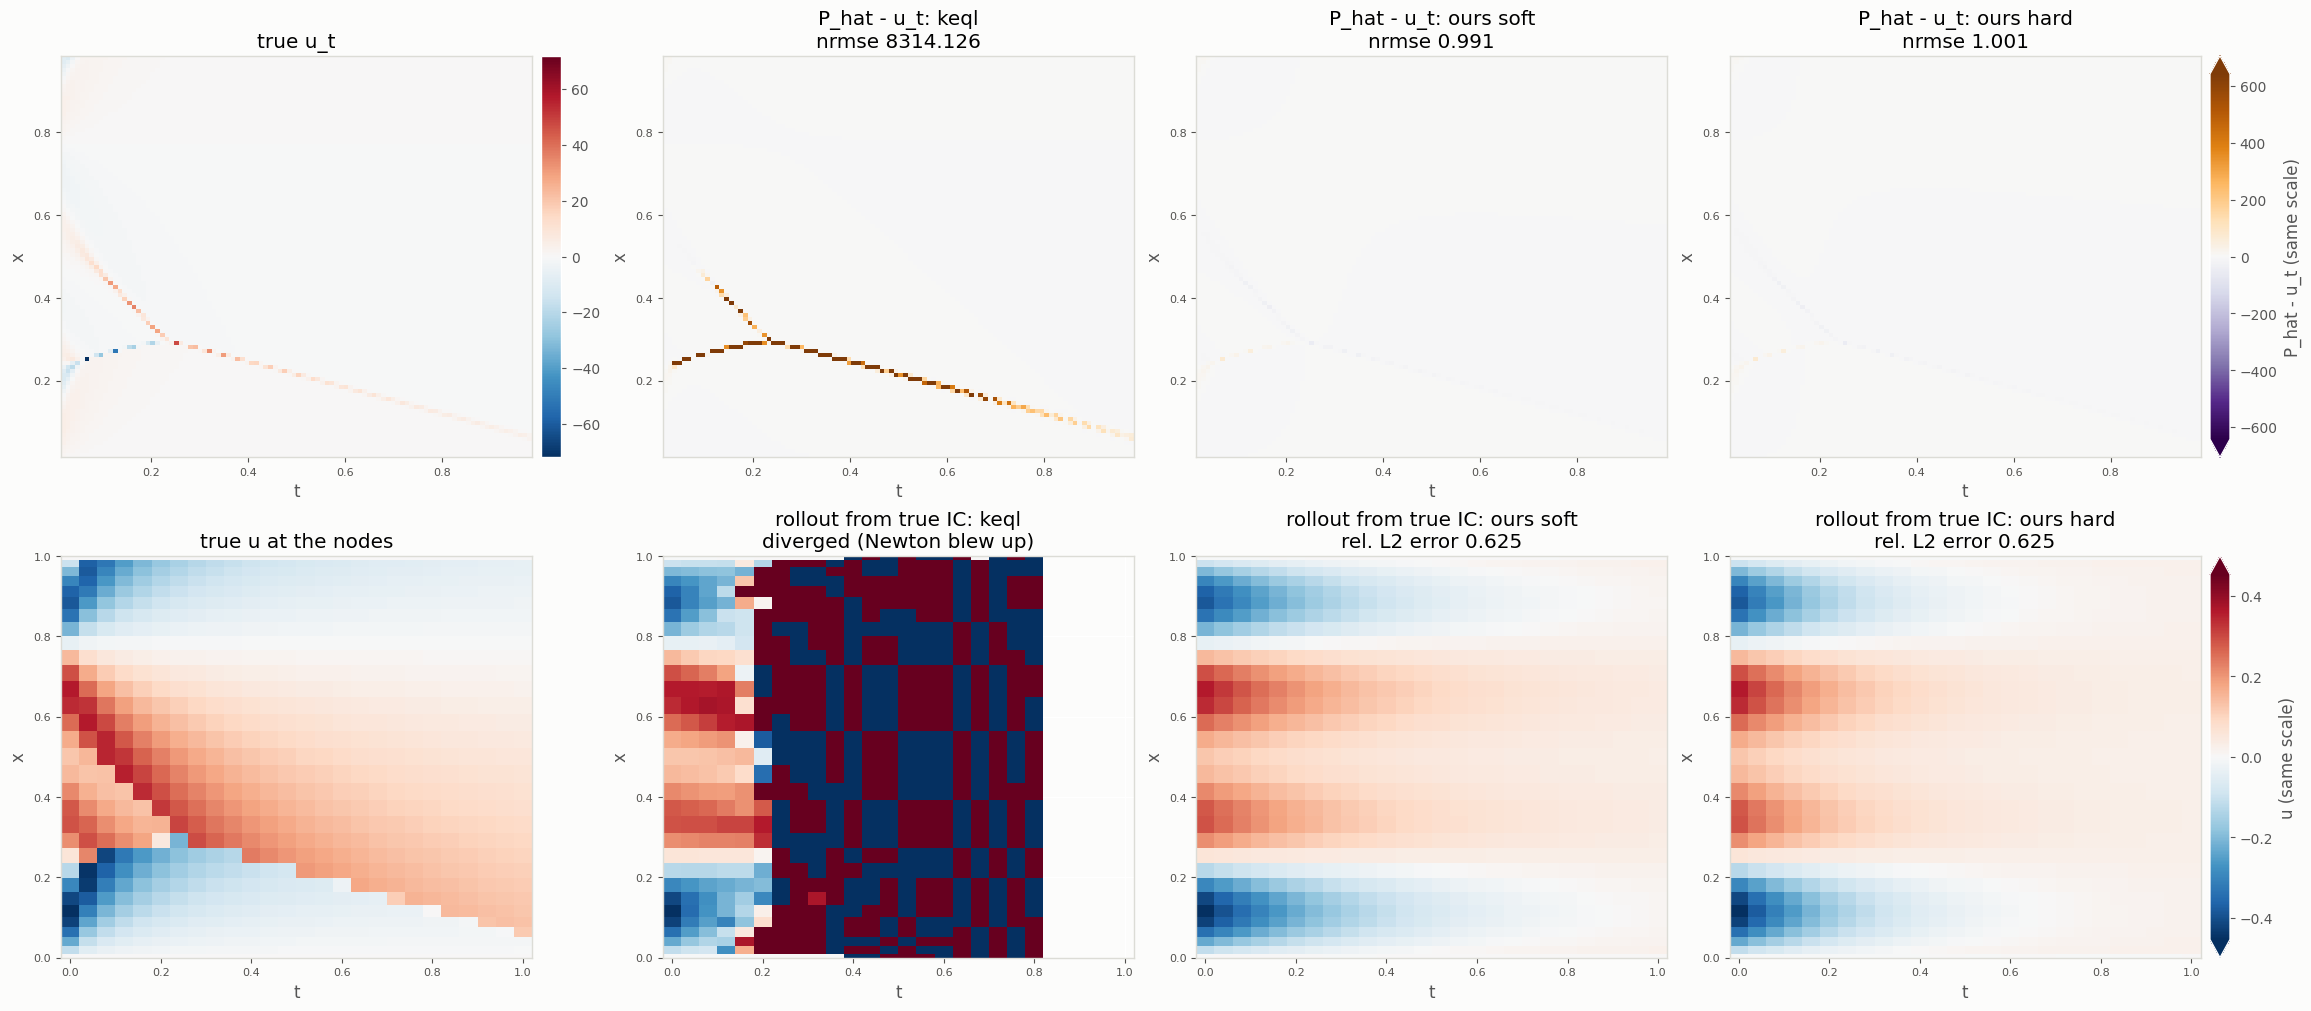

In [8]:
# =====================================================================================
# 2-step method, Step 2 HARD: operator fitted THROUGH the Crank-Nicolson rollout (state frozen at alpha_bar)
# =====================================================================================
# Operator: the KMD operator with the atoms selected by 2-step soft (ACTIVE, fixed here); only their coefficients
#   b_A = (beta_m, m in ACTIVE) are unknowns, beta_m = 0 for m not in ACTIVE:
#   P_hat(s) = Psi(s) b = sum_{m in ACTIVE} phi_m(z_{i(m)})^T beta_m,   s = (u, u_x, u_xx, u_xxx).
# Step map alpha_{n+1} = Phi(alpha_n; b) (note p.5): Newton on the dynamic residual (note p.3), in u space:
#   e(alpha_{n+1}; b) = K (alpha_{n+1} - alpha_n) - dt [ theta_n r(alpha_{n+1}; b) + (1 - theta_n) r(alpha_n; b) ] = 0,
#   r(alpha_n; b) = [0; P_hat(s(x_k; alpha_n)), k = 1..29; 0],   theta_n = THETA = 1/2.
# NEWTON_ITERS = 6 iterations from alpha^(0) = alpha_n, with (1 - theta_n) r(alpha_n; b) computed once. For m = 0..5:
#   (1) s(x_k; alpha^(m)) with D0, D1, D2, D3;  (2) r(alpha^(m); b) and e(alpha^(m); b);
#   (3) dr/dalpha (jax.jacfwd through P_hat and D0..D3) and J(alpha^(m); b) = K - dt theta_n dr/dalpha;
#   (4) solve J delta = -e,  alpha^(m+1) = alpha^(m) + delta.      alpha_{n+1} = alpha^(6).
# The same stepper is built for any operator P_hat (make_stepper): ours (KMD, b in R^NB) and keql's degree-2 psi form
#   (b in R^10; keql's P_hat and the true operator have exact coordinates in psi), so all rollouts use the same Phi.
# Rollout: alpha_0 = alpha_bar_0,  alpha_n = Phi^n(alpha_bar_0; b), n = 1..25 (no data used after t = 0).
# Loss (note p.7):
#   J(b) = sum_{n=1}^{25} || K alpha_bar_n - K Phi^n(alpha_bar_0; b) ||^2 + lambda_beta sum_{m in ACTIVE} beta_m^T K_m beta_m,
#   lambda_beta = LAM_BETA_2H (fixed).  The RKHS penalty is written as || L_A^T b_A ||^2 with KREG_A = L_A L_A^T
#   (= || b_A ||^2 for the constant and linear atoms).
# J is nonlinear in b (through the rollout): trust-region Gauss-Newton (scipy least_squares) on the residual vector
#   [ K alpha_bar_n - K Phi^n(alpha_bar_0; b), n = 1..25 ;  sqrt(lambda_beta) L_A^T b_A ],   exact Jacobian via jax.jacfwd.
from scipy.optimize import least_squares
from jax import lax

NEWTON_ITERS = 6
LAM_BETA_2H = 1e-6         # lambda_beta: weight on sum_{m in ACTIVE} beta_m^T K_m beta_m
MAX_NFEV = 300

K_j, D_j = jnp.asarray(K), [jnp.asarray(D) for D in D_all]               # D0, D1, D2, D3
c_j, sig_j = jnp.asarray(c_bar), jnp.asarray(sig_bar)
COLS = cols_of(ACTIVE)                                                 # positions of b_A inside b (R^NB)
NA = len(COLS)
KREG_A = KREG[np.ix_(COLS, COLS)]
L_A = jnp.asarray(np.linalg.cholesky(KREG_A + 1e-10 * np.eye(NA)))      # KREG_A = L_A L_A^T
embed = lambda bA: jnp.zeros(NB).at[COLS].set(bA)                     # b_A -> b (zeros off ACTIVE)

def psi_j(S):                                                          # keql's degree-2 feature map psi(), in jax: (..., 3) -> (..., 10)
    z = (S - c_j) / sig_j; z1, z2, z3 = z[..., 0], z[..., 1], z[..., 2]; r2 = jnp.sqrt(2.0)
    return jnp.stack([jnp.ones_like(z1), r2 * z1, r2 * z2, r2 * z3, z1 ** 2, z2 ** 2, z3 ** 2,
                      r2 * z1 * z2, r2 * z1 * z3, r2 * z2 * z3], -1)

P_ours_j = lambda S4, b: Psi(S4, ACTIVE) @ b                           # ours: KMD operator, b in R^NB
P_psi_j = lambda S4, b: psi_j(S4[..., :3]) @ b                         # keql / true operator in psi coordinates, b in R^10

def make_stepper(P_hat):
    """Step map Phi(alpha_n; b) and rollout for the operator P_hat(S4, b)."""
    def r(alpha, b):                                                   # r(alpha; b) in R^31
        S4 = jnp.stack([D @ alpha for D in D_j], -1)                   # (1) (29, 4) features s(x_k; alpha)
        return jnp.concatenate([jnp.zeros(1), P_hat(S4, b), jnp.zeros(1)])   # zero boundary rows

    def Phi(alpha_n, b):                                               # alpha_{n+1} = Phi(alpha_n; b)
        r_old = (1 - THETA) * r(alpha_n, b)                            # (1 - theta_n) r(alpha_n; b), computed once
        a = alpha_n                                                    # alpha^(0) = alpha_n
        for _ in range(NEWTON_ITERS):
            e = K_j @ (a - alpha_n) - DT * (THETA * r(a, b) + r_old)   # (2) e(alpha^(m); b)
            J = K_j - DT * THETA * jax.jacfwd(r)(a, b)                 # (3) J(alpha^(m); b)
            a = a + jnp.linalg.solve(J, -e)                            # (4) J delta = -e,  alpha^(m+1) = alpha^(m) + delta
        return a

    @jax.jit
    def rollout(a0, b):                                                # (26, 31): row n = Phi^n(a0; b), n = 0..25
        _, As = lax.scan(lambda a, _: (Phi(a, b),) * 2, a0, None, length=N_T - 1)
        return jnp.vstack([a0[None], As])
    return Phi, rollout

Phi, rollout = make_stepper(P_ours_j)                                  # ours (b in R^NB)
Phi_psi, rollout_psi = make_stepper(P_psi_j)                           # keql / true operator (b in R^10)

a0_bar = jnp.asarray(alpha_bar[:, 0])
U_tgt = jnp.asarray(u_bar[1:])                                         # (25, 31) K alpha_bar_n, n = 1..25
def resid(bA):
    U_roll = rollout(a0_bar, embed(bA))[1:] @ K_j                      # (25, 31) K Phi^n(alpha_bar_0; b) (K symmetric)
    return jnp.concatenate([(U_tgt - U_roll).ravel(), jnp.sqrt(LAM_BETA_2H) * (L_A.T @ bA)])
rj, Jj = jax.jit(resid), jax.jit(jax.jacfwd(resid))
f = lambda b: np.nan_to_num(np.asarray(rj(jnp.asarray(b))), nan=1e6, posinf=1e6, neginf=-1e6)     # blow-up -> large residual
jac = lambda b: np.nan_to_num(np.asarray(Jj(jnp.asarray(b))))

# warm start from the soft fit b_2s (its rollout is stable now); b = 0 kept as a check that the start does not matter
fits = {}
for tag, b0 in [("from b_2s", b_2s[COLS]), ("from b = 0", np.zeros(NA))]:
    res = least_squares(f, b0, jac=jac, method="trf", x_scale="jac", max_nfev=MAX_NFEV)
    fits[tag] = np.asarray(embed(res.x))                               # stored as b in R^NB (zeros off ACTIVE)
    print(f"hard fit {tag:10s}: nfev {res.nfev:3d},  loss {0.5 * np.sum(f(b0) ** 2):.3e} -> {res.cost:.3e}")
b_2h = fits["from b_2s"]
P_hat_hard = lambda S4: np.asarray(Psi(S4, ACTIVE)) @ b_2h
P_eval["ours hard"] = P_hat_hard(S4_eval)
print("active coefficients (2-step soft | 2-step hard | true):")
for m in ACTIVE:
    sl = slice(B_SLICE[m], B_SLICE[m + 1])
    if ATOMS[m]["nb"] == 1:
        print(f"  {ATOMS[m]['name']:16s} {b_2s[sl][0]: .5e}  {b_2h[sl][0]: .5e}  {b_true_lib[sl][0]: .5e}")
    else:
        print(f"  {ATOMS[m]['name']:16s} ({ATOMS[m]['nb']} coefficients; |beta| soft {np.linalg.norm(b_2s[sl]):.2e}, hard {np.linalg.norm(b_2h[sl]):.2e})")
print(f"operator error (keql metric): ours soft {nrmse(P_eval['ours']):.3f},  ours hard {nrmse(P_eval['ours hard']):.3f},  "
      f"keql {nrmse(P_eval['keql']):.3f};   |b_hard(from b_2s) - b_hard(from 0)| / |b_hard| = "
      f"{np.linalg.norm(fits['from b_2s'] - fits['from b = 0']) / np.linalg.norm(b_2h):.1e}")

# ---- rollouts from the TRUE initial column, all in our Crank–Nicolson stepper.
#      keql's P_hat (and the true operator) are exactly quadratic in (u, u_x, u_xx): marched in psi coordinates (rollout_psi).
alpha0_true = jnp.asarray(np.linalg.solve(K, u_true_nodes[0]))
S_gen = c_bar + np.random.default_rng(0).standard_normal((400, 3)) * sig_bar     # generic points: the psi fit is exact
b_keql_psi = np.linalg.lstsq(psi(S_gen, c_bar, sig_bar), P_hat_keql(S_gen), rcond=None)[0]
b_true_psi = np.linalg.lstsq(psi(S_gen, c_bar, sig_bar), P_true(S_gen), rcond=None)[0]
U_floor = np.asarray(rollout_psi(alpha0_true, jnp.asarray(b_true_psi)) @ K_j)         # true equation, same stepper
print(f"stepper floor: true equation rolled out from the true IC, rel. L2 error {rel(U_floor - u_true_nodes, u_true_nodes):.4f}")
U_roll = {"keql": np.asarray(rollout_psi(alpha0_true, jnp.asarray(b_keql_psi)) @ K_j)}         # (26, 31) nodal values
U_roll.update({m: np.asarray(rollout(alpha0_true, jnp.asarray(b)) @ K_j) for m, b in [("ours soft", b_2s), ("ours hard", b_2h)]})

# =====================================================================================
# Visual check.
# Row 1: operator error P_hat(s_true) - u_t on keql's 100 x 100 grid (signed, one shared scale), title = nrmse.
# Row 2: truth at the nodes and the rollout of each learned operator from the true initial column (one shared scale),
#        title = relative L2 error of the rollout over all nodes.
# =====================================================================================
ne = len(g_ev)
edges = np.r_[g_ev - (g_ev[1] - g_ev[0]) / 2, g_ev[-1] + (g_ev[1] - g_ev[0]) / 2]
te = np.r_[t[0] - .02, (t[1:] + t[:-1]) / 2, t[-1] + .02]                             # node-grid cell edges
xe = np.r_[x[0], (x[1:] + x[:-1]) / 2, x[-1]]
names = ("keql", "ours soft", "ours hard")
key = {"keql": "keql", "ours soft": "ours", "ours hard": "ours hard"}
elim = max(np.percentile(np.abs(P_eval[key[m]] - ut_eval), 99.5) for m in names)
lim_t, lim_u = np.abs(ut_eval).max(), np.abs(u_true_nodes).max()

fig, ax = plt.subplots(2, 4, figsize=(23, 10), facecolor=SURF, layout="constrained")
im = ax[0, 0].pcolormesh(edges, edges, ut_eval.reshape(ne, ne).T, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim_t, lim_t), shading="flat")
ax[0, 0].set_title("true u_t"); fig.colorbar(im, ax=ax[0, 0], fraction=.046, pad=.02)
for j, m in enumerate(names, start=1):
    e = (P_eval[key[m]] - ut_eval).reshape(ne, ne)
    im = ax[0, j].pcolormesh(edges, edges, e.T, cmap="PuOr_r", norm=TwoSlopeNorm(0, -elim, elim), shading="flat")
    ax[0, j].set_title(f"P_hat - u_t: {m}\nnrmse {nrmse(P_eval[key[m]]):.3f}")
fig.colorbar(im, ax=ax[0, 3], fraction=.046, pad=.02, extend="both", label="P_hat - u_t (same scale)")

im = ax[1, 0].pcolormesh(te, xe, u_true_nodes.T, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim_u, lim_u), shading="flat")
ax[1, 0].set_title("true u at the nodes")
for j, m in enumerate(names, start=1):
    U = U_roll[m]
    im = ax[1, j].pcolormesh(te, xe, np.clip(U, -3 * lim_u, 3 * lim_u).T, cmap="RdBu_r",
                             norm=TwoSlopeNorm(0, -lim_u, lim_u), shading="flat")
    err_r = rel(U - u_true_nodes, u_true_nodes)
    ax[1, j].set_title(f"rollout from true IC: {m}\n" + (f"rel. L2 error {err_r:.3f}" if np.isfinite(err_r) and err_r < 10
                                                          else "diverged (Newton blew up)"))
fig.colorbar(im, ax=ax[1, 3], fraction=.046, pad=.02, extend="both", label="u (same scale)")
for a in ax.ravel():
    a.set(xlabel="t", ylabel="x"); style(a)
plt.show()

## 1-step soft constraint


active coefficients (2-step soft | 1-step soft | true):
  const             6.38312e-02   1.23263e-01   7.12644e-03
  linear[u]        -3.60658e-01  -3.38687e-01   0.00000e+00
CV-chosen lambda_dyn 1.0e-04, lambda_addot 1.0e-10  (CV 4.82e-02; lambda_addot = 0: 4.84e-02; 2-step Step 1: 6.23e-02), L-BFGS nit 12330;  state u / u_x / u_xx 0.4479 / 1.0248 / 0.9995;  operator 0.9897  (2-step soft 0.991, keql 8314.126)


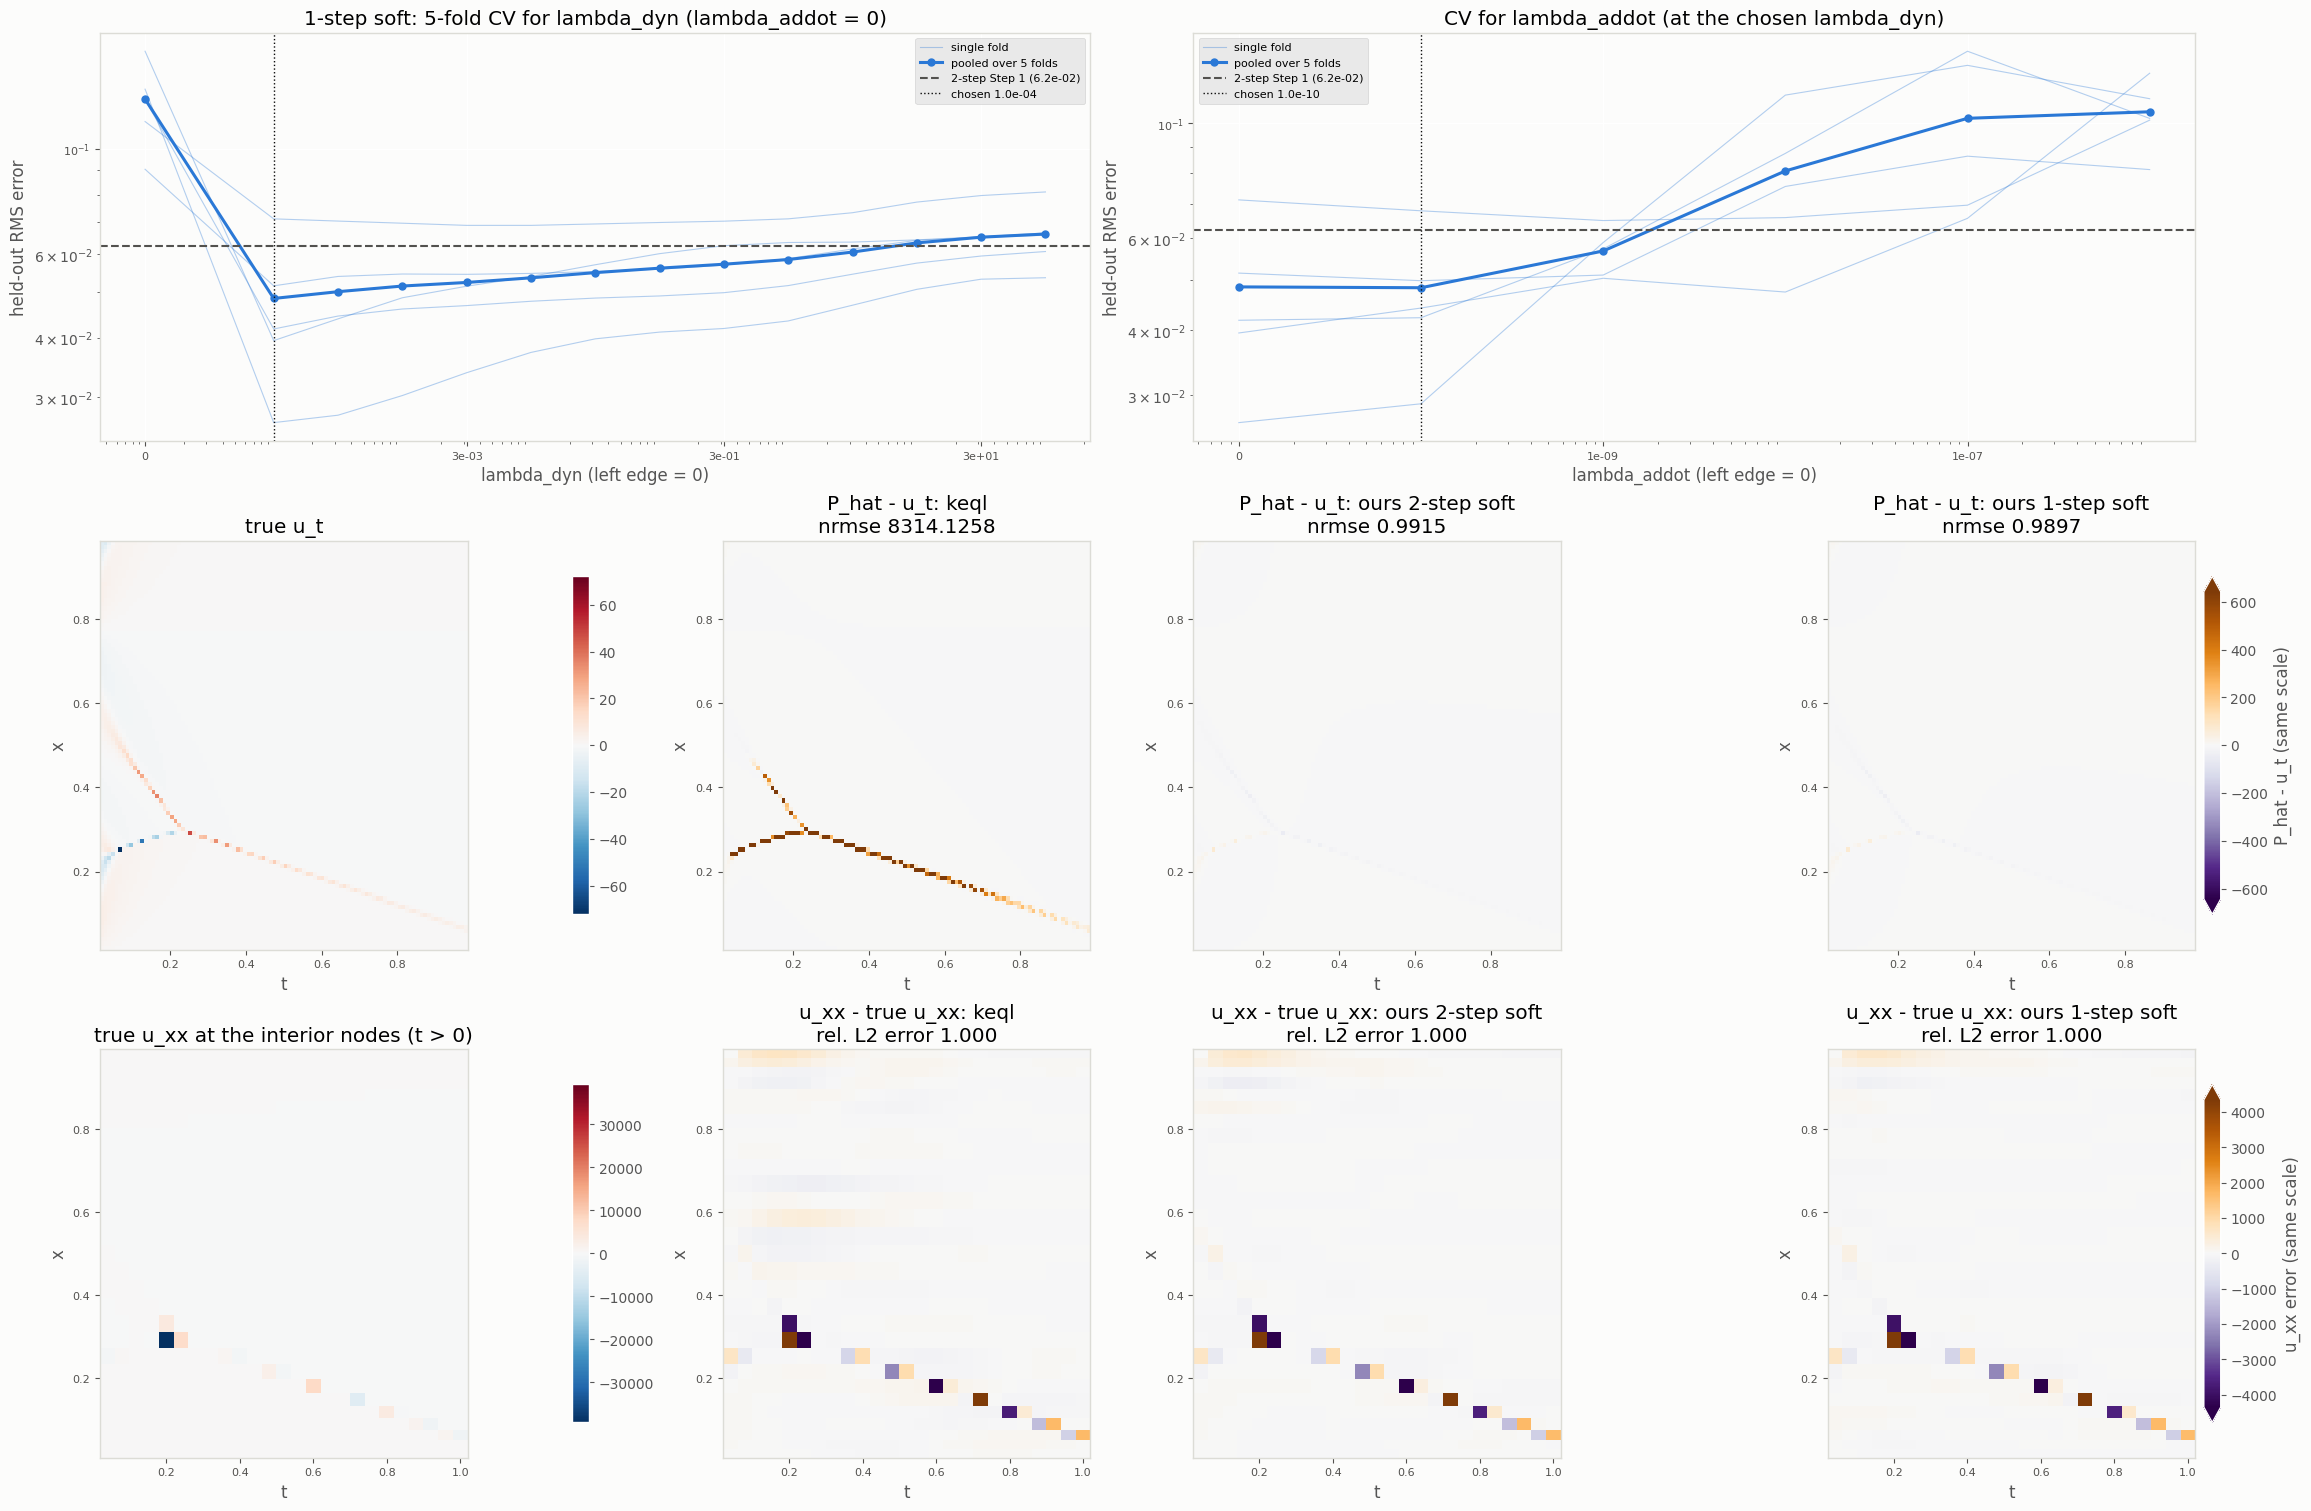

In [9]:
# =====================================================================================
# 1-step method, SOFT constraint: state and operator fitted JOINTLY
# =====================================================================================
# Unknowns: alpha_0, ..., alpha_25 (all 26 columns) and b_A = (beta_m, m in ACTIVE): the KMD operator with the atoms
# selected by 2-step soft (fixed here; beta_m = 0 for m not in ACTIVE),  P_hat(s) = Psi(s) b,  s = (u, u_x, u_xx, u_xxx).
# The library's standardisation (c_lib, sig_lib) and inducing points stay frozen at the Step 1 state's values
# (keql likewise freezes its operator kernel at its initial state).
# Loss (note p.4):
#   J(alpha, b) = lambda_d     sum_{(n,k) in Omega} ( u_obs(t_n, x_k) - u_hat_n(x_k) )^2
#               + lambda_dyn   sum_{n=0}^{24} || e(alpha_{n+1}; b) ||^2
#               + lambda_alpha sum_{n=0}^{25} alpha_n^T K alpha_n  +  lambda_beta sum_{m in ACTIVE} beta_m^T K_m beta_m
#               + lambda_addot / dt^4 sum_{n=1}^{24} || alpha_{n+1} - 2 alpha_n + alpha_{n-1} ||_K^2,
#   e(alpha_{n+1}; b) = K (alpha_{n+1} - alpha_n) - dt [ theta_n r(alpha_{n+1}; b) + (1 - theta_n) r(alpha_n; b) ]  (note p.3),
#   r(alpha_n; b) = [0; P_hat(s(x_k; alpha_n)), k = 1..29; 0],  theta_n = THETA = 1/2.   All 31 rows of e are used: the
#   boundary rows (K alpha_{n+1} - K alpha_n)_{0,30} have no b and hold u = 0 on the boundary.
# Whitened coordinates as in Step 1: alpha_n = L^{-T} w_n (K + 1e-8 I = L L^T), so alpha_n^T K alpha_n ~ ||w_n||^2 and
#   ||v||_K^2 ~ ||L^T v||^2.  Unknowns p = (w_0, ..., w_25, b_A): 806 + NA (NA = 3 on 3A).
# Optimiser: L-BFGS-B on the scalar loss with its exact gradient (jax.value_and_grad), started from the 2-step soft
#   solution (alpha_bar, b_2s restricted to ACTIVE); the loss is divided by its starting value so the tolerances are scale-free.
# Weights: lambda_d = LAM_D = 1 (reference), lambda_alpha = LAM_ALPHA = LAM_U (as in Step 1), lambda_beta = LAM_BETA_1S tiny.
#   By 5-fold CV on the held-out interior observations (same folds as Step 1): (1) lambda_dyn (lambda_addot = 0);
#   (2) lambda_addot at the chosen lambda_dyn.  0 is on both grids (lambda_dyn = 0: no dynamics, each column on its own).
from scipy.optimize import minimize

LAM_D, LAM_ALPHA, LAM_BETA_1S = 1.0, LAM_U, 1e-8          # lambda_d, lambda_alpha, lambda_beta
LAM_DYN_GRID = np.r_[0, np.logspace(-4, 2, 13)]                     # lambda_dyn candidates (half decades)
LAM_ADDOT_GRID = np.unique(np.r_[0, 1e-10, 1e-9, 1e-8, LAM_ADDOT, 1e-7, 1e-6])   # sorted, no duplicates
MAXITER = 20000

LinvT_j = jnp.asarray(LinvT)
K_j, D_j = jnp.asarray(K), [jnp.asarray(D) for D in D_all]               # D0, D1, D2, D3
D_tt_j = jnp.asarray(D_tt)                                             # second difference in time (Step 1 cell)
KREG_A_j = jnp.asarray(KREG_A)                                         # block-diagonal K_m of the active atoms (2-step hard cell)
NW = N_X * N_T

def make_loss(lam_dyn, lam_addot, rows):
    """J(p) using only the observations in `rows` (for CV)."""
    nj, kj, yj = jnp.asarray(n_of[rows]), jnp.asarray(k_of[rows]), jnp.asarray(u_obs[rows])
    def loss(p):
        W = p[:NW].reshape(N_T, N_X); bA = p[NW:]; b = embed(bA)       # W[n] = w_n;  b in R^NB (zeros off ACTIVE)
        al = LinvT_j @ W.T                                             # (31, 26) alpha_n
        U = (K_j @ al).T                                               # (26, 31) nodal values u_hat_n(x_k) = (K alpha_n)_k
        S4 = jnp.stack([(D @ al).T for D in D_j], -1)                  # (26, 29, 4) features s(x_k; alpha_n)
        r = jnp.pad(Psi(S4, ACTIVE) @ b, ((0, 0), (1, 1)))             # (26, 31) row n = r(alpha_n; b) = [0; P_hat(s_n(x_k)); 0]
        e = (U[1:] - U[:-1]) - DT * (THETA * r[1:] + (1 - THETA) * r[:-1])   # (25, 31) row n = e(alpha_{n+1}; b), n = 0..24
        J = LAM_D * jnp.sum((U[nj, kj] - yj) ** 2)
        J += lam_dyn * jnp.sum(e ** 2)
        J += LAM_ALPHA * jnp.sum(W ** 2) + LAM_BETA_1S * bA @ KREG_A_j @ bA
        J += lam_addot / DT ** 4 * jnp.sum((D_tt_j @ W) ** 2)          # optional a-double-dot prior
        return J
    return loss

p_2s = np.r_[(L_chol.T @ alpha_bar).T.ravel(), b_2s[COLS]]             # start: 2-step soft solution
def fit_1soft(lam_dyn, lam_addot=0.0, rows=None, maxiter=MAXITER):
    rows = np.arange(len(u_obs)) if rows is None else rows
    loss = make_loss(lam_dyn, lam_addot, rows)
    vg = jax.jit(jax.value_and_grad(loss))
    s = float(loss(jnp.asarray(p_2s)))                                 # normalise: loss starts at 1
    def obj(p):
        v, g = vg(jnp.asarray(p)); return float(v) / s, np.asarray(g) / s
    res = minimize(obj, p_2s, jac=True, method="L-BFGS-B",
                   options=dict(maxiter=maxiter, maxfun=2 * maxiter, ftol=1e-15, gtol=1e-10))
    return LinvT @ res.x[:NW].reshape(N_T, N_X).T, np.asarray(embed(res.x[NW:])), res   # b returned in R^NB

def cv_1soft(lam_dyn, lam_addot=0.0):
    """5-fold CV: for each fold, fit without its held-out interior observations and predict them.
    Returns the RMS error per fold (5,) and the held-out residuals (100,) in the order of `held`."""
    res_f = []
    for f in folds:                                                    # same folds as Step 1
        al, _, _ = fit_1soft(lam_dyn, lam_addot, np.setdiff1d(np.arange(len(u_obs)), f), maxiter=5000)
        res_f.append((K @ al)[k_of[f], n_of[f]] - u_obs[f])
    return np.array([np.sqrt(np.mean(r ** 2)) for r in res_f]), np.concatenate(res_f)

held = np.concatenate(folds)                                           # held-out interior observations, fold by fold

# ---- (1) CV over lambda_dyn, lambda_addot = 0
cvd_fold, cvd = np.zeros((len(LAM_DYN_GRID), len(folds))), np.zeros(len(LAM_DYN_GRID))
for i, ld in enumerate(LAM_DYN_GRID):
    cvd_fold[i], r = cv_1soft(ld); cvd[i] = np.sqrt(np.mean(r ** 2))
LAM_DYN_1 = LAM_DYN_GRID[np.argmin(cvd)]

# ---- (2) lambda_addot at the chosen lambda_dyn
cvdd_fold, cvdd = np.zeros((len(LAM_ADDOT_GRID), len(folds))), np.zeros(len(LAM_ADDOT_GRID))
for i, la in enumerate(LAM_ADDOT_GRID):
    cvdd_fold[i], r = cv_1soft(LAM_DYN_1, la)
    cvdd[i] = np.sqrt(np.mean(r ** 2))
LAM_ADDOT_1 = LAM_ADDOT_GRID[np.argmin(cvdd)]

alpha_1s, b_1s, res_1s = fit_1soft(LAM_DYN_1, LAM_ADDOT_1)            # final fit on all 181 observations
P_eval["ours 1-step soft"] = Psi_eval @ b_1s                         # P_hat at the true features on keql's grid

def feat(al):
    return np.stack([(D0 @ al).T, (D1 @ al).T, (D2 @ al).T], -1)       # (26, 29, 3)
S_1s = feat(alpha_1s)
print("active coefficients (2-step soft | 1-step soft | true):")
for m in ACTIVE:
    sl = slice(B_SLICE[m], B_SLICE[m + 1])
    if ATOMS[m]["nb"] == 1:
        print(f"  {ATOMS[m]['name']:16s} {b_2s[sl][0]: .5e}  {b_1s[sl][0]: .5e}  {b_true_lib[sl][0]: .5e}")
    else:
        print(f"  {ATOMS[m]['name']:16s} ({ATOMS[m]['nb']} coefficients; |beta| 2-step soft {np.linalg.norm(b_2s[sl]):.2e}, 1-step soft {np.linalg.norm(b_1s[sl]):.2e})")
print(f"CV-chosen lambda_dyn {LAM_DYN_1:.1e}, lambda_addot {LAM_ADDOT_1:.1e}  (CV {cvdd.min():.2e}; lambda_addot = 0: {cvdd[0]:.2e}; "
      f"2-step Step 1: {cv.min():.2e}), L-BFGS nit {res_1s.nit};  state u / u_x / u_xx "
      + " / ".join(f"{rel(S_1s[..., i] - S_true[..., i], S_true[..., i]):.4f}" for i in range(3))
      + f";  operator {nrmse(P_eval['ours 1-step soft']):.4f}  (2-step soft {nrmse(P_eval['ours']):.3f}, keql {nrmse(P_eval['keql']):.3f})")

# =====================================================================================
# Visual check.
# Row 1 (CV process): CV error vs lambda_dyn (lambda_addot = 0) | CV error vs lambda_addot at the chosen lambda_dyn -- thin lines =
#        the 5 folds, thick = pooled, dashed = 2-step Step 1, dotted = chosen, left edge = 0 --
# Row 2: true u_t | P_hat(s_true) - u_t for keql, ours 2-step soft, ours 1-step soft (signed, shared scale, title = nrmse).
# Row 3: true u_xx | u_xx - true u_xx at the interior nodes for the same three (signed, shared scale, t = 0 excluded).
# =====================================================================================
ne = len(g_ev)
edges = np.r_[g_ev - (g_ev[1] - g_ev[0]) / 2, g_ev[-1] + (g_ev[1] - g_ev[0]) / 2]
te = np.r_[t[0] - .02, (t[1:] + t[:-1]) / 2, t[-1] + .02]
xie = np.r_[x_int[0] - (x_int[1] - x_int[0]) / 2, (x_int[1:] + x_int[:-1]) / 2, x_int[-1] + (x_int[-1] - x_int[-2]) / 2]
methods = {"keql": ("keql", S_keql), "ours 2-step soft": ("ours", S_bar), "ours 1-step soft": ("ours 1-step soft", S_1s)}
elim = max(np.percentile(np.abs(P_eval[k] - ut_eval), 99.5) for k, _ in methods.values())
slim = max(np.percentile(np.abs(S[1:, :, 2] - S_true[1:, :, 2]), 99.5) for _, S in methods.values())
lim_t, lim_xx = np.abs(ut_eval).max(), np.abs(S_true[1:, :, 2]).max()

fig = plt.figure(figsize=(23, 15), facecolor=SURF, layout="constrained")
gs = fig.add_gridspec(3, 4)

def cv_panel(a, grid, fold_err, pooled, chosen, name):
    xl = np.r_[grid[1] / 10, grid[1:]]                                 # weight 0 drawn at the left edge
    for j in range(len(folds)):
        a.plot(xl, fold_err[:, j], "-", c=C1, lw=.8, alpha=.35, label="single fold" if j == 0 else None)
    a.plot(xl, pooled, "o-", c=C1, lw=2.2, ms=5, label="pooled over 5 folds")
    a.axhline(cv.min(), c=MUTED, ls="--", label=f"2-step Step 1 ({cv.min():.1e})")
    a.axvline(xl[np.argmin(pooled)], c=INK, lw=1, ls=":", label=f"chosen {chosen:.1e}")
    a.set_xscale("log"); a.set_yscale("log")
    tk = xl[::2] if len(xl) < 10 else xl[::4]
    a.set_xticks(tk, ["0" if v == xl[0] else f"{v:.0e}" for v in tk])
    a.set(xlabel=f"{name} (left edge = 0)", ylabel="held-out RMS error"); a.legend(fontsize=8)

a = fig.add_subplot(gs[0, 0:2])
cv_panel(a, LAM_DYN_GRID, cvd_fold, cvd, LAM_DYN_1, "lambda_dyn")
a.set_title("1-step soft: 5-fold CV for lambda_dyn (lambda_addot = 0)")
a = fig.add_subplot(gs[0, 2:4])
cv_panel(a, LAM_ADDOT_GRID, cvdd_fold, cvdd, LAM_ADDOT_1, "lambda_addot")
a.set_title("CV for lambda_addot (at the chosen lambda_dyn)")

a = fig.add_subplot(gs[1, 0])
im = a.pcolormesh(edges, edges, ut_eval.reshape(ne, ne).T, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim_t, lim_t), shading="flat")
a.set(title="true u_t", xlabel="t", ylabel="x"); fig.colorbar(im, ax=a, fraction=.046, pad=.02)
a = fig.add_subplot(gs[2, 0])
im = a.pcolormesh(te[1:], xie, S_true[1:, :, 2].T, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim_xx, lim_xx), shading="flat")
a.set(title="true u_xx at the interior nodes (t > 0)", xlabel="t", ylabel="x"); fig.colorbar(im, ax=a, fraction=.046, pad=.02)
for j, (m, (key, S)) in enumerate(methods.items(), start=1):
    a = fig.add_subplot(gs[1, j])
    im = a.pcolormesh(edges, edges, (P_eval[key] - ut_eval).reshape(ne, ne).T, cmap="PuOr_r",
                      norm=TwoSlopeNorm(0, -elim, elim), shading="flat")
    a.set(title=f"P_hat - u_t: {m}\nnrmse {nrmse(P_eval[key]):.4f}", xlabel="t", ylabel="x")
    if j == 3: fig.colorbar(im, ax=a, fraction=.046, pad=.02, extend="both", label="P_hat - u_t (same scale)")
    a = fig.add_subplot(gs[2, j])
    E = S[1:, :, 2] - S_true[1:, :, 2]
    im = a.pcolormesh(te[1:], xie, E.T, cmap="PuOr_r", norm=TwoSlopeNorm(0, -slim, slim), shading="flat")
    a.set(title=f"u_xx - true u_xx: {m}\nrel. L2 error {rel(E, S_true[1:, :, 2]):.3f}", xlabel="t", ylabel="x")
    if j == 3: fig.colorbar(im, ax=a, fraction=.046, pad=.02, extend="both", label="u_xx error (same scale)")
for a_ in fig.axes:
    if a_.get_label() != "<colorbar>": style(a_)
plt.show()

## 1-step hard constraint

In [10]:
%%run_if EXPERIMENT == "3A"
# =====================================================================================
# 1-step method, HARD constraint: every column is the Crank-Nicolson rollout of (alpha_0, b)
# =====================================================================================
# Unknowns: alpha_0 (31) and b_A = (beta_m, m in ACTIVE) -- 31 + NA numbers (NA = 3 on 3A).  Operator: the KMD operator
#   with the atoms selected by 2-step soft (fixed here; beta_m = 0 for m not in ACTIVE),  P_hat(s) = Psi(s) b.
#  Every later column is alpha_n = Phi^n(alpha_0; b), with the step map
#   Phi from the 2-step hard cell (Newton in u space on e(alpha_{n+1}; b) = 0, note p.5), so e = 0 holds exactly.
# Loss (note p.5):
#   J(alpha_0, b) = lambda_d     sum_{(n,k) in Omega} ( u_obs(t_n, x_k) - u_hat_n(x_k) )^2
#                 + lambda_alpha sum_{n=0}^{25} alpha_n^T K alpha_n  +  lambda_beta sum_{m in ACTIVE} beta_m^T K_m beta_m
#                 + lambda_addot / dt^4 sum_{n=1}^{24} || alpha_{n+1} - 2 alpha_n + alpha_{n-1} ||_K^2,
#   where alpha_n = Phi^n(alpha_0; b),  u_hat_n(x_k) = (K alpha_n)_k.
# Least-squares form (||v||_K^2 ~ ||L^T v||^2, K + 1e-8 I = L L^T), residual vector
#   [ sqrt(lambda_d) (u_hat_n(x_k) - u_obs) ;  sqrt(lambda_alpha) L^T alpha_n ;  sqrt(lambda_beta) L_A^T b_A ;
#     sqrt(lambda_addot) / dt^2 L^T (alpha_{n+1} - 2 alpha_n + alpha_{n-1}) ],
#   minimised by trust-region Gauss-Newton (scipy least_squares) with the exact Jacobian (jax.jacfwd through the rollout).
#   alpha_0 is whitened, alpha_0 = L^{-T} w_0, so the unknowns are p = (w_0, b_A);  KREG_A = L_A L_A^T (2-step hard cell).
# Start: the 1-step soft solution (alpha_1s[:, 0], b_1s on ACTIVE); (alpha_bar_0, b_2h on ACTIVE) is run as a check that the start does not matter.
# Weights: lambda_d = LAM_D = 1 (reference), lambda_alpha = LAM_ALPHA (= LAM_U), lambda_beta = LAM_BETA_1H = 1e-8 (fixed);
#   lambda_addot by the same 5-fold CV on held-out interior observations as Step 1 and 1-step soft (0 is on the grid).
LAM_BETA_1H = 1e-8
LAM_ADDOT_1H_GRID = np.unique(np.r_[0, 1e-10, 1e-9, 1e-8, LAM_ADDOT, 1e-7, 1e-6])   # sorted, no duplicates
MAX_NFEV_1H = 100

L_j = jnp.asarray(L_chol); LinvT_j = jnp.asarray(LinvT); D_tt_j = jnp.asarray(D_tt)

def traj(p):                                                           # (26, 31): row n = alpha_n = Phi^n(alpha_0; b)
    return rollout(LinvT_j @ p[:N_X], embed(p[N_X:]))                  # rollout(a0, b) from the 2-step hard cell, b = embed(b_A)

def make_resid(lam_addot, rows):
    """Residual vector of J for the observations in `rows` (for CV)."""
    nj, kj, yj = jnp.asarray(n_of[rows]), jnp.asarray(k_of[rows]), jnp.asarray(u_obs[rows])
    def resid(p):
        A = traj(p)                                                    # (26, 31) alpha_n
        U = A @ K_j                                                    # (26, 31) u_hat_n(x_k) = (K alpha_n)_k
        W = A @ L_j                                                    # (26, 31) row n = L^T alpha_n
        return jnp.concatenate([np.sqrt(LAM_D) * (U[nj, kj] - yj),
                                np.sqrt(LAM_ALPHA) * W.ravel(),
                                np.sqrt(LAM_BETA_1H) * (L_A.T @ p[N_X:]),
                                np.sqrt(lam_addot) / DT ** 2 * (D_tt_j @ W).ravel()])
    return resid

def fit_1hard(lam_addot, rows=None, p0=None, max_nfev=MAX_NFEV_1H):
    rows = np.arange(len(u_obs)) if rows is None else rows
    p0 = np.r_[L_chol.T @ alpha_1s[:, 0], b_1s[COLS]] if p0 is None else p0   # start: 1-step soft
    rf = make_resid(lam_addot, rows)
    rj, Jj = jax.jit(rf), jax.jit(jax.jacfwd(rf))
    f = lambda p: np.nan_to_num(np.asarray(rj(jnp.asarray(p))), nan=1e6, posinf=1e6, neginf=-1e6)   # blow-up -> large
    jac = lambda p: np.nan_to_num(np.asarray(Jj(jnp.asarray(p))))
    res = least_squares(f, p0, jac=jac, method="trf", x_scale="jac", max_nfev=max_nfev)
    return res.x, res, 0.5 * np.sum(f(p0) ** 2)

def cv_1hard(lam_addot):
    """5-fold CV (same folds as Step 1): RMS per fold (5,) and held-out residuals (100,) in the order of `held`."""
    res_f = []
    for f_ in folds:
        p, _, _ = fit_1hard(lam_addot, np.setdiff1d(np.arange(len(u_obs)), f_))
        res_f.append(np.asarray(traj(jnp.asarray(p)) @ K)[n_of[f_], k_of[f_]] - u_obs[f_])
    return np.array([np.sqrt(np.mean(r ** 2)) for r in res_f]), np.concatenate(res_f)

# ---- lambda_addot by 5-fold CV
cvh_fold, cvh, cvh_res = np.zeros((len(LAM_ADDOT_1H_GRID), len(folds))), np.zeros(len(LAM_ADDOT_1H_GRID)), {}
for i, la in enumerate(LAM_ADDOT_1H_GRID):
    cvh_fold[i], r_ = cv_1hard(la)
    cvh[i] = np.sqrt(np.mean(r_ ** 2)); cvh_res[la] = r_
LAM_ADDOT_1H = LAM_ADDOT_1H_GRID[np.argmin(cvh)]

# ---- final fit on all 181 observations, from 1-step soft and (check) from (alpha_bar_0, b_2h)
fits_1h = {}
for tag, p0 in [("from 1-step soft", None), ("from (alpha_bar_0, b_2h)", np.r_[L_chol.T @ alpha_bar[:, 0], b_2h[COLS]])]:
    p, res, c0 = fit_1hard(LAM_ADDOT_1H, p0=p0, max_nfev=300)
    fits_1h[tag] = p
    print(f"1-step hard {tag:26s}: nfev {res.nfev:3d},  loss {c0:.3e} -> {res.cost:.3e}")
p_1h = fits_1h["from 1-step soft"]
alpha_1h, b_1h = np.asarray(traj(jnp.asarray(p_1h))).T, np.asarray(embed(p_1h[N_X:]))   # (31, 26) alpha_n, b in R^NB
S_1h = feat(alpha_1h)
P_eval["ours 1-step hard"] = Psi_eval @ b_1h                         # P_hat at the true features on keql's grid
print("active coefficients (1-step soft | 1-step hard | true):")
for m in ACTIVE:
    sl = slice(B_SLICE[m], B_SLICE[m + 1])
    if ATOMS[m]["nb"] == 1:
        print(f"  {ATOMS[m]['name']:16s} {b_1s[sl][0]: .5e}  {b_1h[sl][0]: .5e}  {b_true_lib[sl][0]: .5e}")
    else:
        print(f"  {ATOMS[m]['name']:16s} ({ATOMS[m]['nb']} coefficients; |beta| 1-step soft {np.linalg.norm(b_1s[sl]):.2e}, 1-step hard {np.linalg.norm(b_1h[sl]):.2e})")
print(f"CV-chosen lambda_addot {LAM_ADDOT_1H:.1e}  (CV {cvh.min():.2e}; lambda_addot = 0: {cvh[0]:.2e}; 1-step soft {cvdd.min():.2e});  "
      f"|b(from soft) - b(from 2-step hard)| / |b| = "
      f"{np.linalg.norm(fits_1h['from 1-step soft'][N_X:] - fits_1h['from (alpha_bar_0, b_2h)'][N_X:]) / np.linalg.norm(b_1h):.1e}")
print(f"state u / u_x / u_xx " + " / ".join(f"{rel(S_1h[..., i] - S_true[..., i], S_true[..., i]):.4f}" for i in range(3))
      + f";  operator {nrmse(P_eval['ours 1-step hard']):.4f}  (1-step soft {nrmse(P_eval['ours 1-step soft']):.4f}, "
      f"2-step hard {nrmse(P_eval['ours hard']):.3f}, keql {nrmse(P_eval['keql']):.3f})")

# rollouts from the TRUE initial column (same stepper), for 1-step soft and 1-step hard
U_roll["ours 1-step soft"] = np.asarray(rollout(alpha0_true, jnp.asarray(b_1s)) @ K_j)
U_roll["ours 1-step hard"] = np.asarray(rollout(alpha0_true, jnp.asarray(b_1h)) @ K_j)

# =====================================================================================
# Visual check.
# Row 1: true u_t | P_hat(s_true) - u_t for ours 2-step hard, 1-step soft, 1-step hard (signed, shared scale, title = nrmse).
# Row 2: CV error vs lambda_addot (thin = 5 folds, thick = pooled, dashed = 1-step soft, dotted = chosen, left edge = 0)
#        | u_xx - true u_xx at the interior nodes for the same three (signed, shared scale, t = 0 excluded).
# Row 3: true u at the nodes | 1-step hard state (= its own rollout from the fitted alpha_0) - truth
#        | rollout from the TRUE initial column minus truth: 1-step soft, 1-step hard (signed, shared scale).
# =====================================================================================
ne = len(g_ev)
edges = np.r_[g_ev - (g_ev[1] - g_ev[0]) / 2, g_ev[-1] + (g_ev[1] - g_ev[0]) / 2]
te = np.r_[t[0] - .02, (t[1:] + t[:-1]) / 2, t[-1] + .02]
xie = np.r_[x_int[0] - (x_int[1] - x_int[0]) / 2, (x_int[1:] + x_int[:-1]) / 2, x_int[-1] + (x_int[-1] - x_int[-2]) / 2]
xe = np.r_[x[0], (x[1:] + x[:-1]) / 2, x[-1]]
ops = {"ours 2-step hard": "ours hard", "ours 1-step soft": "ours 1-step soft", "ours 1-step hard": "ours 1-step hard"}
states = {"ours 2-step hard": S_bar, "ours 1-step soft": S_1s, "ours 1-step hard": S_1h}   # 2-step hard uses the Step 1 state
elim = max(np.percentile(np.abs(P_eval[v] - ut_eval), 99.5) for v in ops.values())
slim = max(np.percentile(np.abs(S[1:, :, 2] - S_true[1:, :, 2]), 99.5) for S in states.values())
lim_t, lim_u = np.abs(ut_eval).max(), np.abs(u_true_nodes).max()
U_1h = alpha_1h.T @ K                                                  # (26, 31) 1-step hard state at the nodes
uerr = {"1-step hard state (own rollout)": U_1h - u_true_nodes,
        "rollout from true IC: 1-step soft": U_roll["ours 1-step soft"] - u_true_nodes,
        "rollout from true IC: 1-step hard": U_roll["ours 1-step hard"] - u_true_nodes}
ulim = max(np.percentile(np.abs(v), 99.5) for v in uerr.values())

fig, ax = plt.subplots(3, 4, figsize=(23, 15), facecolor=SURF, layout="constrained")
im = ax[0, 0].pcolormesh(edges, edges, ut_eval.reshape(ne, ne).T, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim_t, lim_t), shading="flat")
ax[0, 0].set(title="true u_t", xlabel="t", ylabel="x"); fig.colorbar(im, ax=ax[0, 0], fraction=.046, pad=.02)
for j, (m, key) in enumerate(ops.items(), start=1):
    im = ax[0, j].pcolormesh(edges, edges, (P_eval[key] - ut_eval).reshape(ne, ne).T, cmap="PuOr_r",
                             norm=TwoSlopeNorm(0, -elim, elim), shading="flat")
    ax[0, j].set(title=f"P_hat - u_t: {m}\nnrmse {nrmse(P_eval[key]):.4f}", xlabel="t", ylabel="x")
fig.colorbar(im, ax=ax[0, 3], fraction=.046, pad=.02, extend="both", label="P_hat - u_t (same scale)")

a = ax[1, 0]
xl = np.r_[LAM_ADDOT_1H_GRID[1] / 10, LAM_ADDOT_1H_GRID[1:]]           # lambda_addot = 0 drawn at the left edge
for j in range(len(folds)):
    a.loglog(xl, cvh_fold[:, j], "-", c=C1, lw=.8, alpha=.35, label="single fold" if j == 0 else None)
a.loglog(xl, cvh, "o-", c=C1, lw=2.2, ms=5, label="1-step hard, pooled")
a.axhline(cvdd.min(), c=MUTED, ls="--", label=f"1-step soft ({cvdd.min():.1e})")
a.axvline(xl[np.argmin(cvh)], c=INK, lw=1, ls=":", label=f"chosen {LAM_ADDOT_1H:.1e}")
a.set_xticks(xl[::2], ["0" if v == xl[0] else f"{v:.0e}" for v in xl[::2]])
a.set(title="1-step hard: 5-fold CV for lambda_addot", xlabel="lambda_addot (left edge = 0)", ylabel="held-out RMS error")
a.legend(fontsize=8)
for j, (m, S) in enumerate(states.items(), start=1):
    E = S[1:, :, 2] - S_true[1:, :, 2]
    im = ax[1, j].pcolormesh(te[1:], xie, E.T, cmap="PuOr_r", norm=TwoSlopeNorm(0, -slim, slim), shading="flat")
    ax[1, j].set(title=f"u_xx - true u_xx: {m}\nrel. L2 error {rel(E, S_true[1:, :, 2]):.4f}", xlabel="t", ylabel="x")
fig.colorbar(im, ax=ax[1, 3], fraction=.046, pad=.02, extend="both", label="u_xx error (same scale)")

im = ax[2, 0].pcolormesh(te, xe, u_true_nodes.T, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim_u, lim_u), shading="flat")
ax[2, 0].set(title="true u at the nodes", xlabel="t", ylabel="x"); fig.colorbar(im, ax=ax[2, 0], fraction=.046, pad=.02)
for j, (m, E) in enumerate(uerr.items(), start=1):
    im = ax[2, j].pcolormesh(te, xe, E.T, cmap="PuOr_r", norm=TwoSlopeNorm(0, -ulim, ulim), shading="flat")
    ax[2, j].set(title=f"{m} - truth\nrel. L2 error {rel(E, u_true_nodes):.4f}", xlabel="t", ylabel="x")
fig.colorbar(im, ax=ax[2, 3], fraction=.046, pad=.02, extend="both", label="u error (same scale)")
for a_ in ax.ravel(): style(a_)
plt.show()

skipped (condition false: EXPERIMENT == "3A")


## keql 1-step

In [11]:
# =====================================================================================
# keql's 1-step method (paper eq. 12; errors_curves.ipynb settings), on the same data and state model as keql's 2-step
# =====================================================================================
# Unknowns: keql's space-time state coefficients (u_model, 2418) and the operator coefficients at the 754 tx_int points.
# Operator kernel: the degree-2 polynomial kernel scaled on the 2-step state's features at tx_int (frozen), acting on
#   (u, u_x, u_xx); the PDE residual is d_t u - P(u, u_x, u_xx) at tx_int; data misfit weighted by datafit_weight = 100.
# Optimiser: CholeskyLM (201 iterations) then SVD_LM (201), beta = 1e-11, started from the 2-step state and P = 0.
# The Jacobian uses keql's batched JVP (build_batched_jac_func(32)); plain jacrev needs ~14 GB.
# SLOW: ~55 min on a 2-core CPU. The result is saved to KEQL1_FILE; if that file exists, it is loaded instead of refitting
#   (delete it, or set REFIT_KEQL1 = True, to refit).
import os
from EquationModel import OperatorPDEModel, build_batched_jac_func
from Optimizers import CholeskyLM, SVD_LM, LMParams

KEQL1_FILE = f"keql1_{EXPERIMENT}.npz"
REFIT_KEQL1 = False

feat_2s_keql = u_model.evaluate_operators((eval_k, dx_k, dxx_k), jnp.asarray(tx_int), u_params_keql
                                          ).reshape(len(tx_int), 3, order="F")            # (754, 3) 2-step features
k_P1_u = get_centered_scaled_poly_kernel(2, feat_2s_keql, c=1., scaling="diagonal")
@vectorize_kfunc
def k_P1(a, b_):
    return k_P1_u(a[2:], b_[2:])                                                          # kernel sees (u, u_x, u_xx) only
P1_model = OperatorModel(k_P1)
Eqn = OperatorPDEModel(P1_model, (u_model,), (jnp.asarray(tx_obs),), (jnp.asarray(u_obs),), (jnp.asarray(tx_int),),
                       (eval_k, dx_k, dxx_k), rhs_operator=dt_k, datafit_weight=100,
                       jacobian_operator=build_batched_jac_func(32))

if os.path.exists(KEQL1_FILE) and not REFIT_KEQL1:
    _d = np.load(KEQL1_FILE)
    u_params_keql1, beta_keql1 = jnp.asarray(_d["u1"]), jnp.asarray(_d["P1"])
    print(f"keql 1-step: loaded from {KEQL1_FILE}")
else:
    lm_opt = LMParams(max_iter=201, show_progress=True)
    p0 = jnp.hstack([u_params_keql, jnp.zeros(len(tx_int))])
    p1, _ = CholeskyLM(p0.copy(), Eqn, beta=1e-11, optParams=lm_opt)
    p1, _ = SVD_LM(p1, Eqn, beta=1e-11, optParams=lm_opt)
    u_params_keql1, beta_keql1 = p1[:u_model.num_params], p1[u_model.num_params:]
anchors_keql1 = Eqn.single_eqn_features(u_model, u_params_keql1, jnp.asarray(tx_int))    # (754, 5) 1-step features
np.savez(KEQL1_FILE, u1=np.asarray(u_params_keql1), P1=np.asarray(beta_keql1), anch1=np.asarray(anchors_keql1))

def P_hat_keql1(S):                                                    # keql 1-step operator at raw features S (N, 3)
    Sfull = jnp.hstack([jnp.zeros((S.shape[0], 2)), jnp.asarray(S)])  # (t, x) slots are ignored by k_P1
    return np.asarray(P1_model.predict_new(Sfull, anchors_keql1, beta_keql1))

# state and features at our nodes, operator on keql's metric grid
u_keql1 = np.asarray(u_model.point_evaluate(jnp.asarray(nodes), u_params_keql1)).reshape(N_T, N_X)
S_keql1 = np.asarray(u_model.evaluate_operators((eval_k, dx_k, dxx_k), jnp.asarray(nodes_int), u_params_keql1)
                     ).reshape(3, N_T, N_X - 2).transpose(1, 2, 0)                        # (26, 29, 3)
P_eval["keql 1-step"] = P_hat_keql1(S_eval)

# keql 1-step's P_hat is exactly quadratic in (u, u_x, u_xx), so it has coordinates in our psi basis (for the rollout)
b_keql1_psi = np.linalg.lstsq(psi(S_gen, c_bar, sig_bar), P_hat_keql1(S_gen), rcond=None)[0]
check("keql 1-step P_hat in psi coordinates (relative)",
      np.abs(psi(S_eval, c_bar, sig_bar) @ b_keql1_psi - P_eval["keql 1-step"]).max() / np.abs(P_eval["keql 1-step"]).max(), tol=1e-8)
print(f"keql 1-step: operator error {nrmse(P_eval['keql 1-step']):.3f} (keql 2-step {nrmse(P_eval['keql']):.3f});  state u / u_x / u_xx "
      + " / ".join(f"{rel(S_keql1[..., i] - S_true[..., i], S_true[..., i]):.3f}" for i in range(3)))

if "KEQL_EXPERIMENT" not in os.environ:                                 # manual run only (automatic runs have no browser to download to)
    from google.colab import files; files.download(KEQL1_FILE)

keql 1-step: loaded from keql1_3B.npz


[OK ] keql 1-step P_hat in psi coordinates (relative): 1.07e-15
keql 1-step: operator error 4791.140 (keql 2-step 8314.126);  state u / u_x / u_xx 0.535 / 1.156 / 1.003


## Full comparison

In [12]:
%%run_if EXPERIMENT == "3A"
# =====================================================================================
# Comparison: all our methods vs keql 2-step and keql 1-step (run after the keql 1-step cell)
# =====================================================================================
# Methods:
#   keql 2-step        state = keql's space-time GP (Step 1),    operator = keql's eq. 13 fit (P_hat_keql)
#   keql 1-step        state = keql's space-time GP, refitted jointly (u_params_keql1), operator = P_hat_keql1 (eq. 12)
#   (ours: KMD operator P_hat(s) = Psi(s) b on the atoms ACTIVE selected by 2-step soft, s = (u, u_x, u_xx, u_xxx))
#   ours 2-step soft   state = alpha_bar (Step 1),               operator = b_2s
#   ours 2-step hard   state = alpha_bar (same Step 1 state),    operator = b_2h
#   ours 1-step soft   state = alpha_1s,                         operator = b_1s
#   ours 1-step hard   state = alpha_1h = Phi^n(alpha_0; b_1h),  operator = b_1h
# Everything is evaluated on the same points: the 26 time columns t_n x 401 points in x (ours only exists at the columns).
#   R_eql    (keql)     : ||P_hat(u) - P(u)|| / ||P(u)||: P_hat at the TRUE features vs true u_t on keql's 100 x 100 grid
#                         linspace(0, 1, 104)[2:-2] in (t, x)  (= nrmse(P_eval[...]) from the earlier cells)
#   R_filter (keql)     : ||u_hat - u|| / ||u|| on keql's 300 x 300 grid linspace(0, 1, 300) in (t, x), t = 0 and x = 0, 1
#                         included. keql's state is a space-time function; ours exists only at the 26 columns t_n, so for
#                         this metric our nodal values are interpolated in t by a cubic spline through the columns
#                         (adds interpolation error to ours only).  Both are keql's nrmse = sqrt(mean err^2 / mean true^2).
#   u at t_n            : ||u_hat - u|| / ||u|| at the 26 columns only (no interpolation: same points for every method)
#   u_xx reconstruction : the method's state u_hat_xx vs true u_xx
#   u_t reconstruction  : the model's u_t along its OWN state, P_hat(u_hat, u_hat_x, u_hat_xx), vs true u_t
#                         (what the method would feed a time stepper; mixes state and operator error)
#   rollout             : the learned operator marched from the TRUE initial column with our CN stepper (Phi), no data after t = 0
# Evaluation window, as in keql's errors_curves.ipynb:
#   u and the rollout (no derivatives): the whole grid, t = 0 and x = 0, 1 included (keql: 300 x 300 over [0, 1]^2).
#   derivative quantities (u_xx, u_t): keql's operator-metric window t, x in [g_ev[0], g_ev[-1]] = [0.019, 0.981]
#     (keql trims 2 points at every edge of linspace(0, 1, 104)): on our columns n = 1..24. The reference solution's
#     spline derivatives are unreliable at the edges (e.g. true u_xx = -26853 at (t, x) = (0, 0)).
#   The t = 0 column (inside the x window) is reported separately for u_t, so errors there stay visible.
# Colours: one hue per family (keql orange, ours 2-step blue, ours 1-step aqua); soft = solid line / circle,
#   hard = dashed line / square; keql 1-step = dash-dot / triangle. Error maps show |prediction - truth| on a log scale,
#   one shared scale per figure; the dashed rectangle marks the evaluation window where one is used.
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from scipy.interpolate import CubicSpline

xf = np.linspace(0, 1, 401)
Bf = [gram(k_state, xf, x), gram(d1, xf, x), gram(d2, xf, x), gram(d3, xf, x)]   # (401, 31): our basis and its x-derivatives (to 3rd) on xf
WIN_T = (t >= g_ev[0]) & (t <= g_ev[-1])                              # keql's window in t: columns n = 1..24
WIN_X = (xf >= g_ev[0]) & (xf <= g_ev[-1])                            # keql's window in x
METHODS = {  # name: (our state alpha, or keql's (state params, operator function, psi coordinates); our b or None; colour, ls, marker)
    "keql 2-step":      ((u_params_keql,  P_hat_keql,  b_keql_psi),  None, C2, "-",  "o"),
    "keql 1-step":      ((u_params_keql1, P_hat_keql1, b_keql1_psi), None, C2, "-.", "^"),
    "ours 2-step soft": (alpha_bar, b_2s, C1, "-",  "o"),
    "ours 2-step hard": (alpha_bar, b_2h, C1, "--", "s"),
    "ours 1-step soft": (alpha_1s,  b_1s, C3, "-",  "o"),
    "ours 1-step hard": (alpha_1h,  b_1h, C3, "--", "s"),
}

def keql_fine(op, prm):                                                # keql's state (or a derivative) on (t_n, xf), (26, 401)
    return np.stack([np.asarray(u_model.evaluate_operators(
        (op,), jnp.stack([jnp.full(len(xf), t[n]), jnp.asarray(xf)], 1), prm)).ravel() for n in range(N_T)])

# ---- fields on (t_n, xf), all (26, 401)
tru_u, tru_uxx, tru_ut = tru.u(t, xf), tru.u_xx(t, xf), tru.u_t(t, xf)
U_rec, Uxx_rec, Ut_rec, U_rol, div_at = {}, {}, {}, {}, {}
for m, (al, b, *_ ) in METHODS.items():
    if isinstance(al, tuple):                                          # keql: space-time state + its own operator
        prm, P_fn, b_roll = al                                         # b_roll: keql's P_hat in psi coordinates
        S = np.stack([keql_fine(op, prm) for op in (eval_k, dx_k, dxx_k)], -1)   # (26, 401, 3)
        Ut_rec[m] = P_fn(S.reshape(-1, 3)).reshape(N_T, len(xf))
    else:
        S = np.stack([(Bi @ al).T for Bi in Bf], -1)                   # (26, 401, 4): (u, u_x, u_xx, u_xxx)
        Ut_rec[m] = np.asarray(Psi(S, ACTIVE)) @ b                     # KMD operator along the method's own state
        b_roll = b
    U_rec[m], Uxx_rec[m] = S[..., 0], S[..., 2]
    roll = rollout_psi if isinstance(al, tuple) else rollout          # keql: psi coordinates; ours: KMD operator
    A = np.asarray(roll(alpha0_true, jnp.asarray(b_roll)))             # (26, 31) alpha_n of the rollout from the true IC
    F = (Bf[0] @ A.T).T
    bad = ~np.all(np.isfinite(F), 1) | (np.abs(F).max(1) > 10 * np.abs(tru_u).max())
    div_at[m] = int(np.argmax(bad)) if bad.any() else None             # first diverged column, or None
    if div_at[m] is not None: F[div_at[m]:] = np.nan
    U_rol[m] = F
# ---- keql's R_filter grid: 300 x 300 over [0, 1]^2 (errors_curves.ipynb, tx_fine)
g300 = np.linspace(0, 1, 300)
tru_300 = tru.u(g300, g300)                                            # (300 t, 300 x)
B300 = gram(k_state, g300, x)                                          # (300, 31) our basis on keql's x grid
def u_300(al):
    if isinstance(al, tuple):                                          # keql: evaluate its space-time state directly
        pts = lambda tt: jnp.stack([jnp.repeat(jnp.asarray(tt), len(g300)), jnp.tile(jnp.asarray(g300), len(tt))], 1)
        return np.concatenate([np.asarray(u_model.point_evaluate(pts(tt), al[0])).reshape(len(tt), len(g300))
                               for tt in np.array_split(g300, 15)])    # 15 batches of 20 times (keeps kernel matrices small)
    return CubicSpline(t, (B300 @ al).T, axis=0)(g300)                 # ours: columns t_n, cubic spline in t
R_filter = {m: np.sqrt(np.mean((u_300(al) - tru_300) ** 2) / np.mean(tru_300 ** 2)) for m, (al, *_) in METHODS.items()}
A_fl = np.asarray(rollout_psi(alpha0_true, jnp.asarray(b_true_psi)))   # true equation, same stepper: the floor
U_floor_f = (Bf[0] @ A_fl.T).T

def rel_all(F, T):                                                     # relative L2 error over the whole grid
    return np.sqrt(np.sum((F - T) ** 2) / np.sum(T ** 2)) if np.all(np.isfinite(F)) else np.nan
def rel_win(F, T):                                                     # ... over keql's window
    return rel_all(F[np.ix_(WIN_T, WIN_X)], T[np.ix_(WIN_T, WIN_X)])
def rel_t0(F, T):                                                      # ... on the t = 0 column, x in the window
    return rel_all(F[0, WIN_X], T[0, WIN_X])
def rel_t(F, T, xm=slice(None)):                                       # relative L2 error per time column
    return np.sqrt(np.sum((F[:, xm] - T[:, xm]) ** 2, 1) / np.sum(T[:, xm] ** 2, 1))

OP_KEY = {"keql 2-step": "keql", "keql 1-step": "keql 1-step", "ours 2-step soft": "ours", "ours 2-step hard": "ours hard",
          "ours 1-step soft": "ours 1-step soft", "ours 1-step hard": "ours 1-step hard"}   # keys of P_eval
ROLL = "rollout"                                                       # key of the rollout metric
metrics = {m: {"R_eql": nrmse(P_eval[OP_KEY[m]]),                     # keql's R_eql: P_hat at true features, 100 x 100
               "R_filter": R_filter[m],                                # keql's R_filter: state u, 300 x 300
               "u": rel_all(U_rec[m], tru_u),                   # state u at the 26 columns, whole x
               "u_xx": rel_win(Uxx_rec[m], tru_uxx),             # state u_xx, keql's window
               "P̂": rel_win(Ut_rec[m], tru_ut),                       # P_hat along own state, keql's window
               "P̂ at t=0": rel_t0(Ut_rec[m], tru_ut),                 # same, t = 0 column (x in the window)
               ROLL: rel_all(U_rol[m], tru_u)} for m in METHODS}       # from the true IC, whole grid
PANEL = {"R_eql": r"$R_{eql}$: $\hat P$ at true features vs $u_t$",     # summary panel titles
         "R_filter": r"$R_{filter}$: $\hat u$ vs $u$ (300 x 300)",
         "u": r"$\hat u$ vs $u$ at the 26 columns $t_n$",
         "u_xx": r"$\hat u_{xx}$ vs $u_{xx}$  (box)",
         "P̂": r"$\hat P$",
         "P̂ at t=0": r"$\hat P$ at $t=0$",
         ROLL: r"rollout from true $u(0)$ vs $u$"}
floor_roll = rel_all(U_floor_f, tru_u)

# ---- printed tables (same numbers as the summary figure)
cols_ = list(next(iter(metrics.values())))                             # metric order, used by the summary figure
def show(title, cols, heads, floor=False):
    print(title)
    print(f"  {'':18s}" + "".join(f"{h:>10s}" for h in heads))
    for m, v in metrics.items():
        print(f"  {m:18s}" + "".join(f"{('diverged' if np.isnan(v[c]) else f'{v[c]:.2g}'):>10s}" for c in cols))
    if floor:
        print(f"  {'floor (true eq.)':18s}" + "".join(f"{(f'{floor_roll:.2g}' if c == ROLL else ''):>10s}" for c in cols))
    print()
keql_cols = [cols_[0], cols_[1], ROLL]                                 # R_eql, R_filter, rollout
diag_cols = [c for c in cols_ if c not in keql_cols]                   # the other four, whatever their names
show("keql's metrics (relative L2)", keql_cols, ["R_eql", "R_filter", "rollout"], floor=True)
show("Diagnostics (relative L2; u_xx and P̂ in keql's box)", diag_cols, diag_cols)

# =====================================================================================
# Figure 1: summary. One panel per metric, one row per method (log x; lower is better). keql's rollout diverges: marked.
# =====================================================================================
names_m = list(METHODS)
fig, ax = plt.subplots(1, len(cols_), figsize=(3.9 * len(cols_), 4.2), facecolor=SURF, layout="constrained", sharey=True)
for a, c in zip(ax, cols_):
    vals = np.array([metrics[m][c] for m in names_m])
    fin = vals[np.isfinite(vals)]
    lo, hi = fin.min() / 3, fin.max() * 8
    for y, m in enumerate(names_m):
        _, _, col, ls, mk = METHODS[m]
        v = vals[y]
        if np.isfinite(v):
            a.plot([lo, v], [y, y], c=GRID, lw=1, zorder=1)
            a.plot(v, y, mk, ms=10, c=col, mec=SURF, mew=2, zorder=3)
            a.text(v * 1.25, y, f"{v:.2g}", va="center", fontsize=9, color=INK)
        else:
            a.text(lo * 1.1, y, "diverged", va="center", fontsize=9, color=MUTED, style="italic")
    if c == ROLL:
        a.axvline(floor_roll, c=MUTED, ls=":", lw=1.2)
        a.text(floor_roll * 1.1, -0.75, f"floor {floor_roll:.2g}", fontsize=8, color=MUTED, va="center")
    a.set_xscale("log"); a.set_xlim(lo, hi); a.set_title(PANEL[c], fontsize=10.5, loc="left"); a.set_xlabel("relative L2 error (log)")
    style(a)
ax[0].set_yticks(range(len(names_m)), names_m); ax[0].set_ylim(len(names_m) - 0.5, -1.1)
fig.suptitle("Relative L2 error (lower is better)", x=0.01, ha="left", fontsize=12)
fig.text(0.01, -0.02, r"$\hat P = \hat P(\hat u, \hat u_x, \hat u_{xx})$ on the method's own state, vs $u_t$;  "
         r"$\hat u_{xx}$ and $\hat P$ are measured in keql's box $t, x \in [0.02, 0.98]$", fontsize=9, color=MUTED)
plt.show()

# =====================================================================================
# Figures 2-5: space-time maps. Row 1: truth and each method's field; row 2: error over time (all methods, log) and each
# method's |error| map on a log colour scale (shared by all methods in the figure, so ours stays visible next to keql).
# Columns = methods (2-step soft and hard share one state, so the state figures show it once).
# With win=True (derivative quantities): errors are measured in keql's window (dashed rectangle; colour scale from it),
#   the per-time curve uses the window in x and greys out the columns outside it, and titles also give the t = 0 column.
# Error-map titles give the relative L2 error; per-time curves: relative L2 error of each time column.
# =====================================================================================
te_f = np.r_[t[0] - .02, (t[1:] + t[:-1]) / 2, t[-1] + .02]
xe_f = np.r_[xf[0], (xf[1:] + xf[:-1]) / 2, xf[-1]]

def spacetime(title, truth, fields, err, floor=None, obs=False, win=False):   # err: math label of the error, e.g. r"$|\hat u - u|$"
    ms = list(fields)
    sel = np.ix_(WIN_T, WIN_X) if win else (slice(None), slice(None))
    lim = np.abs(truth[sel]).max()
    errs = {m: fields[m] - truth for m in ms}
    emax = np.nanmax([np.nanpercentile(np.abs(e[sel]), 99.5) for e in errs.values() if np.isfinite(e[sel]).any()])
    enorm = LogNorm(emax * 1e-3, emax)                                 # 3 decades of |error|
    fig, ax = plt.subplots(2, len(ms) + 1, figsize=(4.6 * (len(ms) + 1), 8.6), facecolor=SURF, layout="constrained")
    im = ax[0, 0].pcolormesh(te_f, xe_f, np.clip(truth, -3 * lim, 3 * lim).T, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim), shading="flat")
    ax[0, 0].set_title("truth" + (" + obs." if obs else ""))
    if obs: ax[0, 0].scatter(t[n_of], x[k_of], s=7, c=INK, lw=0)
    for j, m in enumerate(ms, start=1):
        F = fields[m]
        ax[0, j].pcolormesh(te_f, xe_f, np.clip(F, -3 * lim, 3 * lim).T, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim), shading="flat")
        ax[0, j].set_title(m)
        im2 = ax[1, j].pcolormesh(te_f, xe_f, np.clip(np.abs(errs[m]), emax * 1e-3, None).T, cmap="Purples", norm=enorm, shading="flat")
        if win:
            e, e0 = rel_win(F, truth), rel_t0(F, truth)
            ax[1, j].add_patch(Rectangle((te_f[1], g_ev[0]), te_f[-2] - te_f[1], g_ev[-1] - g_ev[0], fill=False, ec=INK, ls="--", lw=1))
            ax[1, j].set_title(f"{err}\nrel. L2: {e:.2g} in box, {e0:.2g} at t = 0")
        else:
            e = rel_all(F, truth)
            ax[1, j].set_title(f"{err}\ndiverged at t = {t[div_at[m]]:.2f}" if np.isnan(e) and div_at.get(m) is not None
                               else f"{err}\nrel. L2: {e:.2g}")
    fig.colorbar(im, ax=ax[0, -1], fraction=.046, pad=.02, label=title.split(":")[0])
    fig.colorbar(im2, ax=ax[1, -1], fraction=.046, pad=.02, extend="both", label=err + "  (log scale)")
    a = ax[1, 0]                                                       # error over time, all methods
    xm = WIN_X if win else slice(None)
    for m in ms:
        _, _, c, ls, mk = METHODS[m]
        a.semilogy(t, rel_t(fields[m], truth, xm), ls=ls, marker=mk, ms=4, c=c, lw=2, label=m)
    if floor is not None:
        a.semilogy(t, rel_t(floor, truth, xm), c=MUTED, lw=3, alpha=.5, label="floor (true eq.)")
    if win:
        for n in np.where(~WIN_T)[0]:
            a.axvspan(te_f[n], te_f[n + 1], color=GRID, alpha=.6, lw=0)
    a.set(title="rel. L2 error at each $t_n$" + ("\n(x in box; grey: t outside box)" if win else ""),
          xlabel="t", ylabel="rel. L2 error (log)"); a.legend(fontsize=7)
    for a_ in ax.ravel():
        style(a_)
        if a_ is not ax[1, 0]: a_.set(xlabel="t", ylabel="x")
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    plt.show()

SHARED = "ours 2-step (shared state)"                             # 2-step soft and hard share the Step 1 state
METHODS[SHARED] = (None, None, C1, "-", "o")                           # style entry for that shared column
state_of = lambda R: {"keql 2-step": R["keql 2-step"], "keql 1-step": R["keql 1-step"], SHARED: R["ours 2-step soft"],
                      "ours 1-step soft": R["ours 1-step soft"], "ours 1-step hard": R["ours 1-step hard"]}
spacetime(r"State $\hat u$: each method's reconstructed $u$ (row 1) and its error (row 2)", tru_u, state_of(U_rec),
          r"$|\hat u - u|$", obs=True)
spacetime(r"State $\hat u_{xx}$: each method's reconstructed $u_{xx}$ and its error (rel. L2 in keql's box, dashed)",
          tru_uxx, state_of(Uxx_rec), r"$|\hat u_{xx} - u_{xx}|$", win=True)
del METHODS[SHARED]
spacetime(r"$\hat P(\hat u, \hat u_x, \hat u_{xx})$ vs $u_t$  (error in keql's box, dashed)", tru_ut, Ut_rec,
          r"$|\hat P - u_t|$", win=True)
spacetime(r"Rollout: each learned $\hat P$ stepped from the true $u(0)$ with our CN stepper (no data after t = 0)",
          tru_u, U_rol, r"$|\hat u_{roll} - u|$", floor=U_floor_f)

skipped (condition false: EXPERIMENT == "3A")


## keql 3(B) comparison

ours 1-step hard: not applicable here (its CN rollout cannot march this equation on the 26 x 31 grid)
keql experiment 3B: R_filter (keql's metric)
  keql 2-step                        0.6215
  keql 1-step                        0.5418
  ours 2-step (soft = hard state)    0.4872
  ours 1-step soft                   0.4678
  keql's own printed values (3B):   1-step 0.3968,  2-step 0.6283,  PINN-SR 0.3491


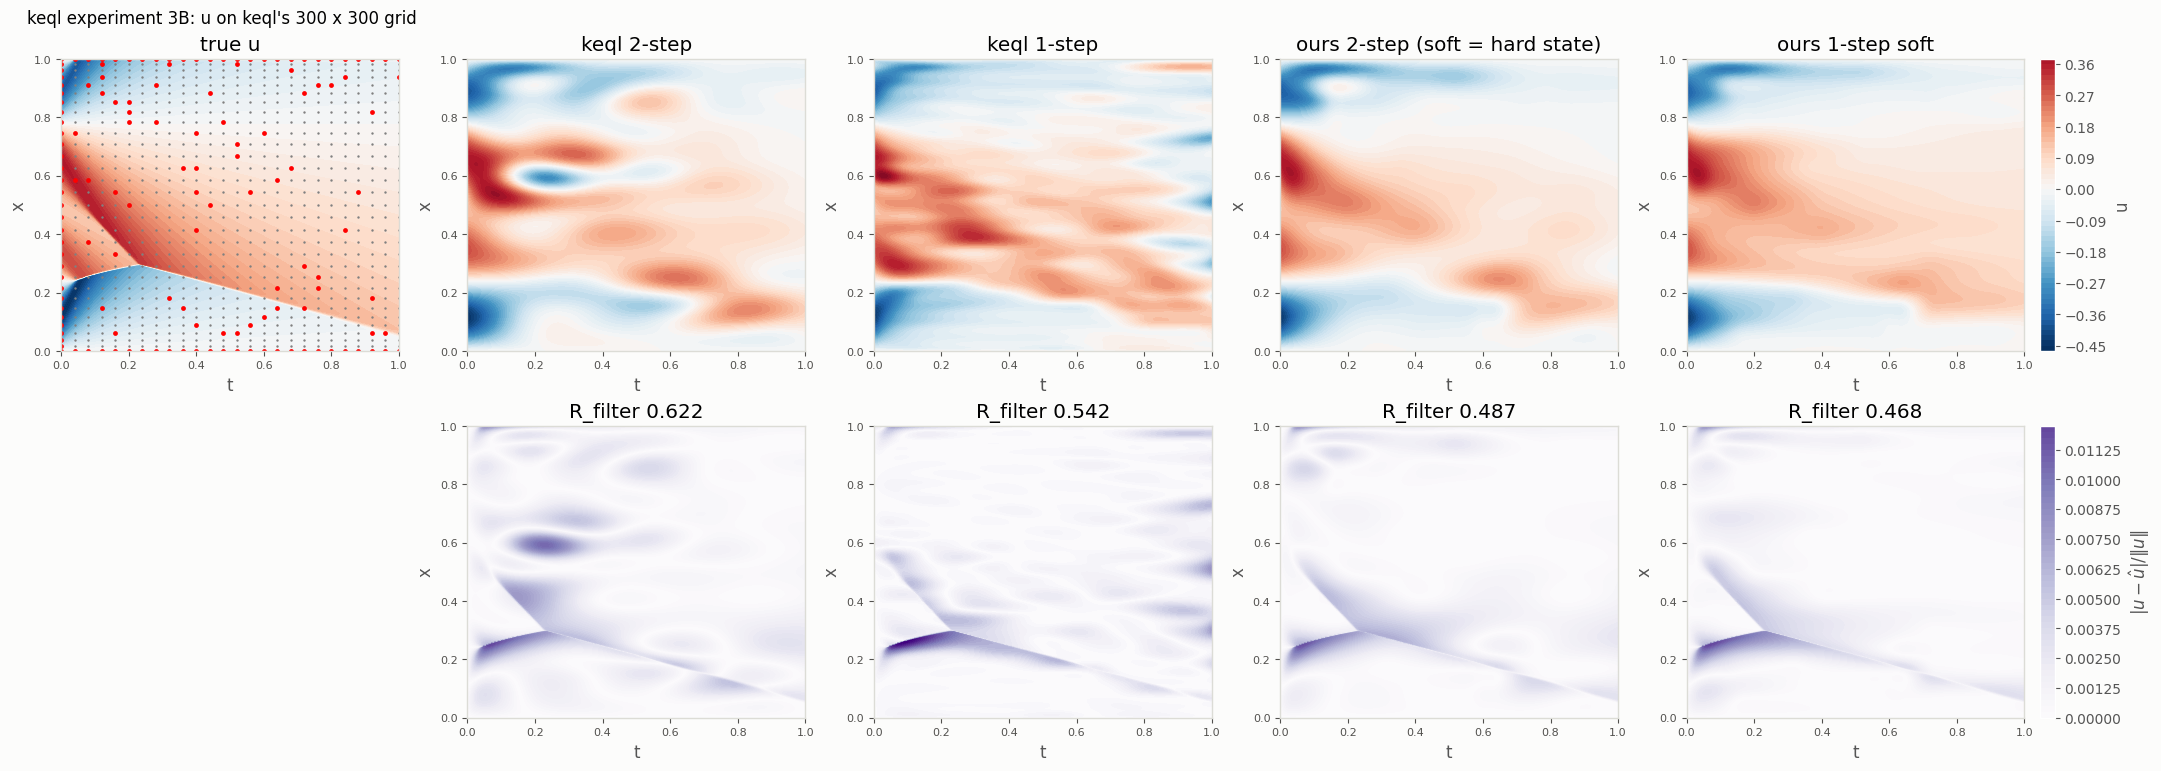

In [13]:
# =====================================================================================
# keql's 3B evaluation (oneshot_shock), exactly what keql measures there, no more:
#   R_filter = get_nrmse(u_true, u_pred) = sqrt(mean (u_true - u_pred)^2 / mean u_true^2) on keql's tx_fine,
#   the 300 x 300 grid meshgrid(linspace(0, 1, 300), linspace(0, 1, 300)) in (t, x);
#   figures: u_pred on that grid, and keql's error map |u_true - u_pred| / ||u_true||.
# (keql's 2-step number is its Step 1 state u_params_init; keql's 1-step number is the joint fit.)
# Our states exist only at the 26 columns t_n: on this grid they are interpolated in t by a cubic spline through the
#   columns (adds interpolation error to ours only). 2-step soft and hard share the Step 1 state, so they share R_filter.
# keql's printed numbers for 3B (oneshot_shock/figs/plot.ipynb): 1-step 0.3968, 2-step 0.6283, PINN-SR 0.3491.
from scipy.interpolate import CubicSpline

t_f, x_f = np.meshgrid(np.linspace(0, 1, 300), np.linspace(0, 1, 300))            # keql's tx_fine, same construction
tx_fine = np.vstack([t_f.ravel(), x_f.ravel()]).T                                  # (90000, 2)
u_true_f = np.asarray(u_true_function(jnp.asarray(tx_fine)))                        # keql's u_true
g300 = np.linspace(0, 1, 300)
B300 = gram(k_state, g300, x)                                                       # (300, 31) our basis on g300
get_nrmse = lambda true, pred: float(np.sqrt(np.mean((true - pred) ** 2) / np.mean(true ** 2)))

def u_pred_keql(prm):                                                               # keql's space-time state on tx_fine
    return np.concatenate([np.asarray(u_model.point_evaluate(jnp.asarray(c), prm)) for c in np.array_split(tx_fine, 30)])

def u_pred_ours(al):                                                                # ours: columns, cubic spline in t
    U = CubicSpline(t, (B300 @ al).T, axis=0)(g300)                                  # (300 t, 300 x)
    return U.T.ravel()                                                               # tx_fine order: row = x, column = t

PRED = {"keql 2-step": u_pred_keql(u_params_keql)}
if "u_params_keql1" in globals(): PRED["keql 1-step"] = u_pred_keql(u_params_keql1)   # from the keql 1-step cell
PRED["ours 2-step (soft = hard state)"] = u_pred_ours(alpha_bar)
PRED["ours 1-step soft"] = u_pred_ours(alpha_1s)
if "alpha_1h" in globals() and np.all(np.isfinite(alpha_1h)):              # 1-step hard: only if its rollout exists
    PRED["ours 1-step hard"] = u_pred_ours(alpha_1h)
else:
    print("ours 1-step hard: not applicable here (its CN rollout cannot march this equation on the 26 x 31 grid)")
R_FILTER = {m: (get_nrmse(u_true_f, p) if np.all(np.isfinite(p)) else np.nan) for m, p in PRED.items()}

print(f"keql experiment {EXPERIMENT}: R_filter (keql's metric)")
for m, v in R_FILTER.items():
    print(f"  {m:34s} {v:.4f}")
print("  keql's own printed values (3B):   1-step 0.3968,  2-step 0.6283,  PINN-SR 0.3491")

# =====================================================================================
# Figure, laid out like keql's Fig. 3B: row 1 = u on keql's 300 x 300 grid (truth with the collocation points in grey and
# observations in red); row 2 = keql's error map |u_true - u_pred| / ||u_true|| (one shared colour scale).
# =====================================================================================
ms = list(PRED)
lim = np.abs(u_true_f).max()
errs = {m: np.abs(u_true_f - p) / np.linalg.norm(u_true_f) for m, p in PRED.items()}
emax = max(np.nanmax(e) for e in errs.values() if np.isfinite(e).any())
fig, ax = plt.subplots(2, len(ms) + 1, figsize=(4.3 * (len(ms) + 1), 7.6), facecolor=SURF, layout="constrained")
im = ax[0, 0].tricontourf(tx_fine[:, 0], tx_fine[:, 1], u_true_f, levels=70, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax[0, 0].scatter(*np.asarray(tx_all).T, c="grey", s=3, lw=0)
ax[0, 0].scatter(*np.asarray(tx_obs).T, c="red", s=12, lw=0)
ax[0, 0].set_title("true u")
ax[1, 0].axis("off")
for j, m in enumerate(ms, start=1):
    p = np.clip(np.nan_to_num(PRED[m], nan=0.0), -lim, lim)
    ax[0, j].tricontourf(tx_fine[:, 0], tx_fine[:, 1], p, levels=70, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax[0, j].set_title(m)
    im2 = ax[1, j].tricontourf(tx_fine[:, 0], tx_fine[:, 1], np.nan_to_num(errs[m], nan=emax), levels=50,
                               cmap="Purples", vmin=0, vmax=emax)
    ax[1, j].set_title(f"R_filter {R_FILTER[m]:.3f}")
fig.colorbar(im, ax=ax[0, -1], fraction=.046, pad=.02, label="u")
fig.colorbar(im2, ax=ax[1, -1], fraction=.046, pad=.02, label=r"$|u - \hat u| / \|u\|$")
for a in ax.ravel():
    if a.axison: a.set(xlabel="t", ylabel="x"); style(a)
fig.suptitle(f"keql experiment {EXPERIMENT}: u on keql's 300 x 300 grid", x=0.01, ha="left", fontsize=12)
plt.show()